## ALURNYA
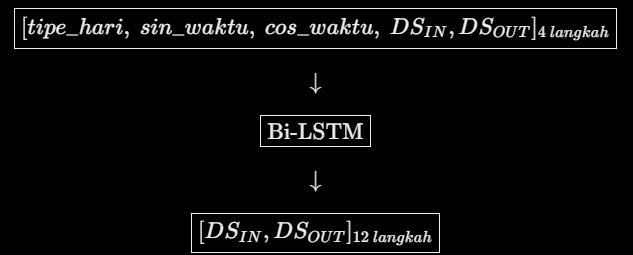

In [21]:
# ============================================================
# CELL 1 - IMPORT LIBRARY & LOAD DATASET MKJI
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np


# ============================================================
# 1. KONFIGURASI PATH
# ============================================================

BASE_DIR = Path(
    r"D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting"
)

DATA_DIR = BASE_DIR / "05_Traffic_Analysis" / "output_mkji_convert_directory"

INPUT_PATH = DATA_DIR / "dataset_mkji.csv"


# ============================================================
# 2. CEK FILE DATASET
# ============================================================

assert INPUT_PATH.exists(), (
    f"Dataset tidak ditemukan:\n{INPUT_PATH}"
)

print("Dataset ditemukan:")
print(INPUT_PATH)


# ============================================================
# 3. LOAD DATASET
# ============================================================

df = pd.read_csv(INPUT_PATH)

print("\nDataset berhasil dimuat.")
print(f"Jumlah baris : {len(df)}")
print(f"Jumlah kolom : {len(df.columns)}")


# ============================================================
# 4. TAMPILKAN STRUKTUR DATASET
# ============================================================

print("\nDaftar kolom:")
print(df.columns.tolist())

print("\n5 data pertama:")
display(df.head())

Dataset ditemukan:
D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\05_Traffic_Analysis\output_mkji_convert_directory\dataset_mkji.csv

Dataset berhasil dimuat.
Jumlah baris : 704
Jumlah kolom : 22

Daftar kolom:
['tanggal', 'waktu', 'sesi', 'tipe_hari', 'MC_IN', 'LV_IN', 'HV_IN', 'MC_OUT', 'LV_OUT', 'HV_OUT', 'Q_IN_15min', 'Q_OUT_15min', 'Q_IN', 'Q_OUT', 'C_IN', 'C_OUT', 'DS_IN', 'DS_OUT', 'LOS_IN', 'LOS_OUT', 'Kondisi_IN', 'Kondisi_OUT']

5 data pertama:


,tanggal,waktu,sesi,tipe_hari,MC_IN,LV_IN,HV_IN,MC_OUT,LV_OUT,HV_OUT,...,Q_IN,Q_OUT,C_IN,C_OUT,DS_IN,DS_OUT,LOS_IN,LOS_OUT,Kondisi_IN,Kondisi_OUT
0,2026-04-06,06:00:00,pagi,0,924,284,34,555,235,18,...,2223.2,1581.4,4791.6,7986.0,0.463979,0.198022,C,B,Arus lalu lintas padat dan pergerakan kendaraa...,Arus mulai sedikit ramai dan kecepatan kendara...
1,2026-04-06,06:15:00,pagi,0,1386,458,19,933,397,16,...,3309.2,2597.8,4791.6,7986.0,0.690625,0.325294,D,C,Arus lalu lintas mendekati kondisi jenuh dan k...,Arus lalu lintas padat dan pergerakan kendaraa...
2,2026-04-06,06:30:00,pagi,0,1826,541,26,1291,446,5,...,4114.8,3099.0,4791.6,7986.0,0.858753,0.388054,E,C,Arus mulai mengalami kemacetan dan kecepatan k...,Arus lalu lintas padat dan pergerakan kendaraa...
3,2026-04-06,06:45:00,pagi,0,2229,541,19,1298,398,11,...,4484.2,2942.8,4791.6,7986.0,0.935846,0.368495,E,C,Arus mulai mengalami kemacetan dan kecepatan k...,Arus lalu lintas padat dan pergerakan kendaraa...
4,2026-04-06,07:00:00,pagi,0,2354,536,26,1432,425,11,...,4622.8,3184.8,4791.6,7986.0,0.964772,0.398798,E,C,Arus mulai mengalami kemacetan dan kecepatan k...,Arus lalu lintas padat dan pergerakan kendaraa...


In [22]:
# ============================================================
# CELL 2 - VALIDASI & PERSIAPAN DATASET
# ============================================================

# ============================================================
# 1. DAFTAR KOLOM YANG DIBUTUHKAN
# ============================================================

required_columns = [
    "tanggal",
    "waktu",
    "sesi",
    "tipe_hari",
    "MC_IN",
    "LV_IN",
    "HV_IN",
    "MC_OUT",
    "LV_OUT",
    "HV_OUT",
    "Q_IN_15min",
    "Q_OUT_15min",
    "Q_IN",
    "Q_OUT",
    "C_IN",
    "C_OUT",
    "DS_IN",
    "DS_OUT",
    "LOS_IN",
    "LOS_OUT"
]


# ============================================================
# 2. KONVERSI TANGGAL & WAKTU
# ============================================================

df["tanggal"] = pd.to_datetime(
    df["tanggal"],
    errors="coerce"
)

df["waktu"] = pd.to_timedelta(
    df["waktu"],
    errors="coerce"
)


# ============================================================
# 3. BUAT DATETIME LENGKAP
# ============================================================

df["datetime"] = (
    df["tanggal"]
    + df["waktu"]
)


# ============================================================
# 4. PASTIKAN DS BERTIPE NUMERIK
# ============================================================

df["DS_IN"] = pd.to_numeric(
    df["DS_IN"],
    errors="coerce"
)

df["DS_OUT"] = pd.to_numeric(
    df["DS_OUT"],
    errors="coerce"
)


# ============================================================
# 5. CEK MISSING VALUE
# ============================================================

print("\n=== MISSING VALUE ===")

check_columns = [
    "tanggal",
    "waktu",
    "datetime",
    "sesi",
    "tipe_hari",
    "DS_IN",
    "DS_OUT"
]

print(df[check_columns].isnull().sum())


# ============================================================
# 6. CEK NILAI UNIK
# ============================================================

print("\n=== TIPE HARI ===")
print(sorted(df["tipe_hari"].dropna().unique()))

print("\n=== SESI ===")
print(df["sesi"].dropna().unique())


# ============================================================
# 7. CEK DUPLIKASI WAKTU
# ============================================================

duplicate_count = df.duplicated(
    subset=["tanggal", "waktu"]
).sum()

print("\n=== DUPLIKASI TANGGAL + WAKTU ===")
print(f"Jumlah duplikasi: {duplicate_count}")


# ============================================================
# 8. URUTKAN DATA SECARA KRONOLOGIS
# ============================================================

df = (
    df
    .sort_values(["tanggal", "waktu"])
    .reset_index(drop=True)
)


# ============================================================
# 9. TAMPILKAN HASIL
# ============================================================

print("\n=== PREVIEW DATA ===")

display(
    df[
        [
            "tanggal",
            "waktu",
            "datetime",
            "sesi",
            "tipe_hari",
            "DS_IN",
            "DS_OUT",
            "LOS_IN",
            "LOS_OUT"
        ]
    ].head(10)
)


=== MISSING VALUE ===
tanggal      0
waktu        0
datetime     0
sesi         0
tipe_hari    0
DS_IN        0
DS_OUT       0
dtype: int64

=== TIPE HARI ===
[np.int64(0), np.int64(1)]

=== SESI ===
['pagi' 'sore']

=== DUPLIKASI TANGGAL + WAKTU ===
Jumlah duplikasi: 0

=== PREVIEW DATA ===


,tanggal,waktu,datetime,sesi,tipe_hari,DS_IN,DS_OUT,LOS_IN,LOS_OUT
0,2026-04-06,0 days 06:00:00,2026-04-06 06:00:00,pagi,0,0.463979,0.198022,C,B
1,2026-04-06,0 days 06:15:00,2026-04-06 06:15:00,pagi,0,0.690625,0.325294,D,C
2,2026-04-06,0 days 06:30:00,2026-04-06 06:30:00,pagi,0,0.858753,0.388054,E,C
3,2026-04-06,0 days 06:45:00,2026-04-06 06:45:00,pagi,0,0.935846,0.368495,E,C
4,2026-04-06,0 days 07:00:00,2026-04-06 07:00:00,pagi,0,0.964772,0.398798,E,C
5,2026-04-06,0 days 07:15:00,2026-04-06 07:15:00,pagi,0,0.948118,0.327323,E,C
6,2026-04-06,0 days 07:30:00,2026-04-06 07:30:00,pagi,0,0.934427,0.340471,E,C
7,2026-04-06,0 days 07:45:00,2026-04-06 07:45:00,pagi,0,0.797437,0.316905,D,C
8,2026-04-06,0 days 08:00:00,2026-04-06 08:00:00,pagi,0,0.740713,0.308089,D,C
9,2026-04-06,0 days 08:15:00,2026-04-06 08:15:00,pagi,0,0.698264,0.277461,D,C


## Feature Engineering
Menambahkan informasi waktu yang akan berguna untuk Bi-LSTM, karena data memiliki sesi pagi dan sore, informasi jam penting agar model dapat membedakan pola lalu lintas berdasarkan waktu.  

Karena waktu merupakan data siklik, bukan benar-benar linear. Setelah pukul 23:59, waktu kembali ke 00:00. Kalau kita hanya memberikan jam sebagai angka, model melihat dari jam 23 langsung ke 0 dan itu sangat jauh nilainya, padahal secara waktu 23:59 itu sangat dekat nilainya dengan 00:00. sehingga dibutuhkan pasangan sinus-cosinus merepresentasikan waktu sebagai posisi pada sebuah lingkaran.

In [23]:
# ============================================================
# CELL 3 - FEATURE ENGINEERING WAKTU
# ============================================================

# ============================================================
# 1. EKSTRAK JAM DAN MENIT
# ============================================================

df["jam"] = df["datetime"].dt.hour
df["menit"] = df["datetime"].dt.minute


# ============================================================
# 2. KONVERSI WAKTU MENJADI MENIT DALAM SEHARI
# ============================================================

df["menit_dalam_hari"] = (
    df["jam"] * 60
    + df["menit"]
)


# ============================================================
# 3. CYCLICAL ENCODING WAKTU
# ============================================================

df["sin_waktu"] = np.sin(
    2 * np.pi * df["menit_dalam_hari"] / 1440
)

df["cos_waktu"] = np.cos(
    2 * np.pi * df["menit_dalam_hari"] / 1440
)


# ============================================================
# 4. CEK HASIL FEATURE ENGINEERING
# ============================================================

print("Feature engineering waktu berhasil.")

print("\nFitur baru:")
print([
    "jam",
    "menit",
    "menit_dalam_hari",
    "sin_waktu",
    "cos_waktu"
])


# ============================================================
# 5. TAMPILKAN DATASET
# ============================================================

display(df.head(10))

Feature engineering waktu berhasil.

Fitur baru:
['jam', 'menit', 'menit_dalam_hari', 'sin_waktu', 'cos_waktu']


,tanggal,waktu,sesi,tipe_hari,MC_IN,LV_IN,HV_IN,MC_OUT,LV_OUT,HV_OUT,...,LOS_IN,LOS_OUT,Kondisi_IN,Kondisi_OUT,datetime,jam,menit,menit_dalam_hari,sin_waktu,cos_waktu
0,2026-04-06,0 days 06:00:00,pagi,0,924,284,34,555,235,18,...,C,B,Arus lalu lintas padat dan pergerakan kendaraa...,Arus mulai sedikit ramai dan kecepatan kendara...,2026-04-06 06:00:00,6,0,360,1.000000,6.123234e-17
1,2026-04-06,0 days 06:15:00,pagi,0,1386,458,19,933,397,16,...,D,C,Arus lalu lintas mendekati kondisi jenuh dan k...,Arus lalu lintas padat dan pergerakan kendaraa...,2026-04-06 06:15:00,6,15,375,0.997859,-6.540313e-02
2,2026-04-06,0 days 06:30:00,pagi,0,1826,541,26,1291,446,5,...,E,C,Arus mulai mengalami kemacetan dan kecepatan k...,Arus lalu lintas padat dan pergerakan kendaraa...,2026-04-06 06:30:00,6,30,390,0.991445,-1.305262e-01
3,2026-04-06,0 days 06:45:00,pagi,0,2229,541,19,1298,398,11,...,E,C,Arus mulai mengalami kemacetan dan kecepatan k...,Arus lalu lintas padat dan pergerakan kendaraa...,2026-04-06 06:45:00,6,45,405,0.980785,-1.950903e-01
4,2026-04-06,0 days 07:00:00,pagi,0,2354,536,26,1432,425,11,...,E,C,Arus mulai mengalami kemacetan dan kecepatan k...,Arus lalu lintas padat dan pergerakan kendaraa...,2026-04-06 07:00:00,7,0,420,0.965926,-2.588190e-01
5,2026-04-06,0 days 07:15:00,pagi,0,2367,526,15,1258,327,10,...,E,C,Arus mulai mengalami kemacetan dan kecepatan k...,Arus lalu lintas padat dan pergerakan kendaraa...,2026-04-06 07:15:00,7,15,435,0.946930,-3.214395e-01
6,2026-04-06,0 days 07:30:00,pagi,0,2327,504,28,1207,366,10,...,E,C,Arus mulai mengalami kemacetan dan kecepatan k...,Arus lalu lintas padat dan pergerakan kendaraa...,2026-04-06 07:30:00,7,30,450,0.923880,-3.826834e-01
7,2026-04-06,0 days 07:45:00,pagi,0,1921,451,20,1046,352,16,...,D,C,Arus lalu lintas mendekati kondisi jenuh dan k...,Arus lalu lintas padat dan pergerakan kendaraa...,2026-04-06 07:45:00,7,45,465,0.896873,-4.422887e-01
8,2026-04-06,0 days 08:00:00,pagi,0,1650,434,34,962,353,18,...,D,C,Arus lalu lintas mendekati kondisi jenuh dan k...,Arus lalu lintas padat dan pergerakan kendaraa...,2026-04-06 08:00:00,8,0,480,0.866025,-5.000000e-01
9,2026-04-06,0 days 08:15:00,pagi,0,1549,406,36,931,302,16,...,D,C,Arus lalu lintas mendekati kondisi jenuh dan k...,Arus lalu lintas padat dan pergerakan kendaraa...,2026-04-06 08:15:00,8,15,495,0.831470,-5.555702e-01


In [24]:
# ============================================================
# CELL 4 - MENENTUKAN FITUR INPUT & TARGET
# ============================================================

# ============================================================
# 1. FITUR INPUT (X)
# ============================================================

fitur_input = [
    "tipe_hari",
    "sin_waktu",
    "cos_waktu",
    "DS_IN",
    "DS_OUT"
]


# ============================================================
# 2. TARGET PREDIKSI (Y)
# ============================================================

target = [
    "DS_IN",
    "DS_OUT"
]


# ============================================================
# 3. VALIDASI KOLOM
# ============================================================

kolom_model = list(dict.fromkeys(fitur_input + target))


# ============================================================
# 4. PASTIKAN SEMUA FITUR NUMERIK
# ============================================================

for col in kolom_model:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )


# ============================================================
# 5. CEK MISSING VALUE
# ============================================================

print("=== MISSING VALUE FITUR MODEL ===")
print(df[kolom_model].isnull().sum())


# ============================================================
# 6. INFORMASI FITUR & TARGET
# ============================================================
print("\n=== FITUR INPUT (X) ===")
for i, col in enumerate(fitur_input, start=1):
    print(f"{i}. {col}")

print("\n=== TARGET (Y) ===")
for i, col in enumerate(target, start=1):
    print(f"{i}. {col}")


# ============================================================
# 7. TAMPILKAN DATA YANG AKAN DIGUNAKAN MODEL
# ============================================================

print("\n=== PREVIEW DATA YANG MASUK KE MODEL ===")

display(
    df[
        [
            "tanggal",
            "waktu",
            "sesi"
        ] + kolom_model
    ].head(10)
)

=== MISSING VALUE FITUR MODEL ===
tipe_hari    0
sin_waktu    0
cos_waktu    0
DS_IN        0
DS_OUT       0
dtype: int64

=== FITUR INPUT (X) ===
1. tipe_hari
2. sin_waktu
3. cos_waktu
4. DS_IN
5. DS_OUT

=== TARGET (Y) ===
1. DS_IN
2. DS_OUT

=== PREVIEW DATA YANG MASUK KE MODEL ===


,tanggal,waktu,sesi,tipe_hari,sin_waktu,cos_waktu,DS_IN,DS_OUT
0,2026-04-06,0 days 06:00:00,pagi,0,1.000000,6.123234e-17,0.463979,0.198022
1,2026-04-06,0 days 06:15:00,pagi,0,0.997859,-6.540313e-02,0.690625,0.325294
2,2026-04-06,0 days 06:30:00,pagi,0,0.991445,-1.305262e-01,0.858753,0.388054
3,2026-04-06,0 days 06:45:00,pagi,0,0.980785,-1.950903e-01,0.935846,0.368495
4,2026-04-06,0 days 07:00:00,pagi,0,0.965926,-2.588190e-01,0.964772,0.398798
5,2026-04-06,0 days 07:15:00,pagi,0,0.946930,-3.214395e-01,0.948118,0.327323
6,2026-04-06,0 days 07:30:00,pagi,0,0.923880,-3.826834e-01,0.934427,0.340471
7,2026-04-06,0 days 07:45:00,pagi,0,0.896873,-4.422887e-01,0.797437,0.316905
8,2026-04-06,0 days 08:00:00,pagi,0,0.866025,-5.000000e-01,0.740713,0.308089
9,2026-04-06,0 days 08:15:00,pagi,0,0.831470,-5.555702e-01,0.698264,0.277461


### Split Train-Test (secara kronologis)

Struktur data terdiri dari beberapa tanggal × sesi dan nantinya satu sampel membutuhkan 4 input + 12 output, sehingga Split harus berdasarkan tanggal secara kronologis, sehingga satu tanggal tidak terpotong antara train dan test.

In [25]:
# ============================================================
# CELL 5 - CHRONOLOGICAL TRAIN-TEST SPLIT
# ============================================================

# ============================================================
# 1. PARAMETER SPLIT
# ============================================================

JUMLAH_HARI_TEST = 2

# ============================================================
# 2. AMBIL DAFTAR TANGGAL UNIK SECARA KRONOLOGIS
# ============================================================

tanggal_unik = np.array(
    sorted(df["tanggal"].dropna().unique())
)

jumlah_tanggal = len(tanggal_unik)

print("=== INFORMASI DATA ===")
print(f"Jumlah tanggal unik : {jumlah_tanggal}")


# ============================================================
# 3. TENTUKAN BATAS TRAIN-TEST
# ============================================================

split_idx = jumlah_tanggal - JUMLAH_HARI_TEST

tanggal_train = tanggal_unik[:split_idx]
tanggal_test = tanggal_unik[split_idx:]


# ============================================================
# 4. BUAT DATA TRAIN & TEST
# ============================================================

df_train = (
    df[df["tanggal"].isin(tanggal_train)]
    .copy()
    .sort_values(["tanggal", "waktu"])
    .reset_index(drop=True)
)

df_test = (
    df[df["tanggal"].isin(tanggal_test)]
    .copy()
    .sort_values(["tanggal", "waktu"])
    .reset_index(drop=True)
)


# ============================================================
# 5. VALIDASI AGAR TANGGAL TIDAK TUMPANG TINDIH
# ============================================================

overlap = set(tanggal_train) & set(tanggal_test)

assert len(overlap) == 0, (
    "Terdapat tanggal yang sama pada train dan test."
)


# ============================================================
# 6. TAMPILKAN HASIL SPLIT
# ============================================================

print("\n=== TRAIN SET ===")
print(f"Tanggal : {len(tanggal_train)}")
print(f"Baris   : {len(df_train)}")
print(
    f"Periode : "
    f"{df_train['tanggal'].min().date()} "
    f"sampai "
    f"{df_train['tanggal'].max().date()}"
)

print("\n=== TEST SET ===")
print(f"Tanggal : {len(tanggal_test)}")
print(f"Baris   : {len(df_test)}")
print(
    f"Periode : "
    f"{df_test['tanggal'].min().date()} "
    f"sampai "
    f"{df_test['tanggal'].max().date()}"
)


# ============================================================
# 7. CEK DISTRIBUSI TIPE HARI
# ============================================================

print("\n=== DISTRIBUSI TIPE HARI - TRAIN ===")
print(
    df_train["tipe_hari"]
    .value_counts()
    .sort_index()
)

print("\n=== DISTRIBUSI TIPE HARI - TEST ===")
print(
    df_test["tipe_hari"]
    .value_counts()
    .sort_index()
)


# ============================================================
# 8. CEK DISTRIBUSI SESI
# ============================================================

print("\n=== DISTRIBUSI SESI - TRAIN ===")
print(df_train["sesi"].value_counts())

print("\n=== DISTRIBUSI SESI - TEST ===")
print(df_test["sesi"].value_counts())

=== INFORMASI DATA ===
Jumlah tanggal unik : 22

=== TRAIN SET ===
Tanggal : 20
Baris   : 640
Periode : 2026-04-06 sampai 2026-04-25

=== TEST SET ===
Tanggal : 2
Baris   : 64
Periode : 2026-04-26 sampai 2026-04-27

=== DISTRIBUSI TIPE HARI - TRAIN ===
tipe_hari
0    480
1    160
Name: count, dtype: int64

=== DISTRIBUSI TIPE HARI - TEST ===
tipe_hari
0    32
1    32
Name: count, dtype: int64

=== DISTRIBUSI SESI - TRAIN ===
sesi
pagi    320
sore    320
Name: count, dtype: int64

=== DISTRIBUSI SESI - TEST ===
sesi
pagi    32
sore    32
Name: count, dtype: int64


_Perbandingan Train : Test = 80 : 20 --> 12 hari train dan 3 hari test._

_jumlah baris:  384 train dan 96 test_

### Scaling Data 
Menggunakan `MinMaxScaler`, tetapi scaler **hanya di-fit pada data train**. kalau data test di-fit juga, maka data test akan bocor ke data train. 

In [26]:
# ============================================================
# CELL 6 - SCALING FITUR INPUT & TARGET
# ============================================================

from sklearn.preprocessing import MinMaxScaler


# ============================================================
# 1. INISIALISASI SCALER
# ============================================================

scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()


# ============================================================
# 2. FIT SCALER HANYA MENGGUNAKAN DATA TRAIN
# ============================================================

scaler_X.fit(df_train[fitur_input])
scaler_y.fit(df_train[target])


# ============================================================
# 3. TRANSFORM DATA TRAIN
# ============================================================

X_train_scaled = scaler_X.transform(
    df_train[fitur_input]
)

y_train_scaled = scaler_y.transform(
    df_train[target]
)


# ============================================================
# 4. TRANSFORM DATA TEST
# ============================================================

X_test_scaled = scaler_X.transform(
    df_test[fitur_input]
)

y_test_scaled = scaler_y.transform(
    df_test[target]
)


# ============================================================
# 5. TAMPILKAN DIMENSI DATA
# ============================================================

print("=== DIMENSI DATA SETELAH SCALING ===")

print("\nTRAIN")
print(f"X_train_scaled : {X_train_scaled.shape}")
print(f"y_train_scaled : {y_train_scaled.shape}")

print("\nTEST")
print(f"X_test_scaled  : {X_test_scaled.shape}")
print(f"y_test_scaled  : {y_test_scaled.shape}")


# ============================================================
# 6. CEK RENTANG DATA TRAIN
# ============================================================

print("\nRENTANG DATA TRAIN")

print(
    f"X train : "
    f"{X_train_scaled.min():.4f} "
    f"sampai "
    f"{X_train_scaled.max():.4f}"
)

print(
    f"y train : "
    f"{y_train_scaled.min():.4f} "
    f"sampai "
    f"{y_train_scaled.max():.4f}"
)


# ============================================================
# 7. CEK RENTANG DATA TEST
# ============================================================

print("\nRENTANG DATA TEST")

print(
    f"X test : "
    f"{X_test_scaled.min():.4f} "
    f"sampai "
    f"{X_test_scaled.max():.4f}"
)

print(
    f"y test : "
    f"{y_test_scaled.min():.4f} "
    f"sampai "
    f"{y_test_scaled.max():.4f}"
)

=== DIMENSI DATA SETELAH SCALING ===

TRAIN
X_train_scaled : (640, 5)
y_train_scaled : (640, 2)

TEST
X_test_scaled  : (64, 5)
y_test_scaled  : (64, 2)

RENTANG DATA TRAIN
X train : 0.0000 sampai 1.0000
y train : 0.0000 sampai 1.0000

RENTANG DATA TEST
X test : 0.0000 sampai 1.0000
y test : 0.0002 sampai 0.8308


## Membentuk Sequence (4 input → 12 output)

In [27]:
# ============================================================
# CELL 7 - MEMBENTUK SEQUENCE 4 INPUT -> 12 OUTPUT
# ============================================================

INPUT_STEPS = 4
OUTPUT_STEPS = 12


# ============================================================
# 1. FUNGSI PEMBUATAN SEQUENCE
# ============================================================

def create_sequences(
    df_data,
    X_scaled,
    y_scaled,
    input_steps=4,
    output_steps=12
):
    X_sequences = []
    y_sequences = []
    metadata = []

    # DataFrame sementara untuk menyimpan posisi array scaled
    temp = df_data.copy().reset_index(drop=True)
    temp["_scaled_idx"] = np.arange(len(temp))

    # Sequence dibuat terpisah untuk setiap tanggal dan sesi
    for (tanggal, sesi), group in temp.groupby(
        ["tanggal", "sesi"],
        sort=False
    ):
        group = group.sort_values("waktu").reset_index(drop=True)

        indices = group["_scaled_idx"].to_numpy()

        total_steps = input_steps + output_steps

        # Pastikan jumlah interval mencukupi
        if len(group) < total_steps:
            print(
                f"Skip: {tanggal.date()} - {sesi} "
                f"hanya memiliki {len(group)} interval."
            )
            continue

        # Sliding window
        for start in range(len(group) - total_steps + 1):

            input_idx = indices[
                start : start + input_steps
            ]

            output_idx = indices[
                start + input_steps :
                start + total_steps
            ]

            X_sequences.append(
                X_scaled[input_idx]
            )

            y_sequences.append(
                y_scaled[output_idx]
            )

            metadata.append({
                "tanggal": tanggal,
                "sesi": sesi,
                "waktu_input_awal":
                    group.iloc[start]["waktu"],
                "waktu_input_akhir":
                    group.iloc[start + input_steps - 1]["waktu"],
                "waktu_prediksi_awal":
                    group.iloc[start + input_steps]["waktu"],
                "waktu_prediksi_akhir":
                    group.iloc[start + total_steps - 1]["waktu"]
            })

    return (
        np.array(X_sequences),
        np.array(y_sequences),
        pd.DataFrame(metadata)
    )


# ============================================================
# 2. SEQUENCE TRAIN
# ============================================================

X_train_seq, y_train_seq, meta_train = create_sequences(
    df_train,
    X_train_scaled,
    y_train_scaled,
    INPUT_STEPS,
    OUTPUT_STEPS
)


# ============================================================
# 3. SEQUENCE TEST
# ============================================================

X_test_seq, y_test_seq, meta_test = create_sequences(
    df_test,
    X_test_scaled,
    y_test_scaled,
    INPUT_STEPS,
    OUTPUT_STEPS
)


# ============================================================
# 4. TAMPILKAN DIMENSI
# ============================================================

print("=== DIMENSI SEQUENCE ===")

print("\nTRAIN")
print(f"X_train_seq : {X_train_seq.shape}")
print(f"y_train_seq : {y_train_seq.shape}")

print("\nTEST")
print(f"X_test_seq  : {X_test_seq.shape}")
print(f"y_test_seq  : {y_test_seq.shape}")


# ============================================================
# 5. TAMPILKAN METADATA SEQUENCE
# ============================================================

print("\n=== CONTOH SEQUENCE TRAIN ===")
display(meta_train.head())

print("\n=== CONTOH SEQUENCE TEST ===")
display(meta_test.head())

=== DIMENSI SEQUENCE ===

TRAIN
X_train_seq : (40, 4, 5)
y_train_seq : (40, 12, 2)

TEST
X_test_seq  : (4, 4, 5)
y_test_seq  : (4, 12, 2)

=== CONTOH SEQUENCE TRAIN ===


,tanggal,sesi,waktu_input_awal,waktu_input_akhir,waktu_prediksi_awal,waktu_prediksi_akhir
0,2026-04-06,pagi,0 days 06:00:00,0 days 06:45:00,0 days 07:00:00,0 days 09:45:00
1,2026-04-06,sore,0 days 15:00:00,0 days 15:45:00,0 days 16:00:00,0 days 18:45:00
2,2026-04-07,pagi,0 days 06:00:00,0 days 06:45:00,0 days 07:00:00,0 days 09:45:00
3,2026-04-07,sore,0 days 15:00:00,0 days 15:45:00,0 days 16:00:00,0 days 18:45:00
4,2026-04-08,pagi,0 days 06:00:00,0 days 06:45:00,0 days 07:00:00,0 days 09:45:00



=== CONTOH SEQUENCE TEST ===


,tanggal,sesi,waktu_input_awal,waktu_input_akhir,waktu_prediksi_awal,waktu_prediksi_akhir
0,2026-04-26,pagi,0 days 06:00:00,0 days 06:45:00,0 days 07:00:00,0 days 09:45:00
1,2026-04-26,sore,0 days 15:00:00,0 days 15:45:00,0 days 16:00:00,0 days 18:45:00
2,2026-04-27,pagi,0 days 06:00:00,0 days 06:45:00,0 days 07:00:00,0 days 09:45:00
3,2026-04-27,sore,0 days 15:00:00,0 days 15:45:00,0 days 16:00:00,0 days 18:45:00


Catatan: Meskipun data training memiliki 384 baris, model tidak menggunakan setiap baris sebagai satu sampel. Karena setiap sampel membutuhkan 4 interval sebagai input dan 12 interval sebagai target, maka satu sesi yang terdiri dari 16 interval hanya menghasilkan 1 sequence. Dengan 12 hari × 2 sesi, diperoleh 24 sequence training. Oleh karena jumlah sequence relatif sedikit, model Bi-LSTM sebaiknya dibuat sederhana untuk mengurangi risiko overfitting.  

Gunakan model sesederhana mungkin yang masih mampu menangkap pola temporal dengan baik, kemudian buktikan performanya melalui data pengujian. 

model sederhana yang dimaksud adalah model dengan jumlah parameter yang relatif sedikit, sehingga model tidak terlalu kompleks dan lebih mudah untuk dilatih dengan jumlah data yang terbatas, karena kompleksitas model disesuaikan dengan ukuran dataset.

Kesimpulannya, arsitektur Bi-LSTM dibuat relatif sederhana, bukan menumpuk banyak layer/neuron.

## Train & Validation Split
Pembagian Data: Dataset dibagi secara kronologis untuk mempertahankan urutan waktu. Dari 15 hari pengamatan, 10 hari digunakan sebagai training, 2 hari sebagai validation, dan 3 hari sebagai testing. Setiap hari menghasilkan dua sequence, yaitu sesi pagi dan sore, sehingga diperoleh 20 sequence training, 4 sequence validation, dan 6 sequence testing. Data validation digunakan untuk memantau performa model selama pelatihan, sedangkan data testing hanya digunakan untuk evaluasi akhir.

12 hari data train awal → 10 hari training + 2 hari validation, sedangkan 3 hari terakhir tetap testing.

In [28]:
# ============================================================
# CELL 8 - TRAIN & VALIDATION SPLIT BERDASARKAN HARI
# ============================================================

JUMLAH_HARI_VALIDATION = 2


# ============================================================
# 1. AMBIL TANGGAL UNIK DARI METADATA TRAIN
# ============================================================

tanggal_train_seq = np.array(
    sorted(meta_train["tanggal"].unique())
)

print("Jumlah hari pada train awal :", len(tanggal_train_seq))


# ============================================================
# 2. TENTUKAN TANGGAL TRAIN FINAL & VALIDATION
# ============================================================

tanggal_train_final = tanggal_train_seq[
    :-JUMLAH_HARI_VALIDATION
]

tanggal_val = tanggal_train_seq[
    -JUMLAH_HARI_VALIDATION:
]


# ============================================================
# 3. BUAT MASK BERDASARKAN TANGGAL
# ============================================================

mask_train = (
    meta_train["tanggal"]
    .isin(tanggal_train_final)
    .to_numpy()
)

mask_val = (
    meta_train["tanggal"]
    .isin(tanggal_val)
    .to_numpy()
)


# ============================================================
# 4. SPLIT SEQUENCE
# ============================================================

X_train_final = X_train_seq[mask_train]
y_train_final = y_train_seq[mask_train]

X_val = X_train_seq[mask_val]
y_val = y_train_seq[mask_val]


# ============================================================
# 5. SPLIT METADATA
# ============================================================

meta_train_final = (
    meta_train[mask_train]
    .reset_index(drop=True)
)

meta_val = (
    meta_train[mask_val]
    .reset_index(drop=True)
)


# ============================================================
# 6. TAMPILKAN HASIL
# ============================================================

print("\n=== PEMBAGIAN DATA FINAL ===")

print("\nTRAIN")
print(f"Hari     : {len(tanggal_train_final)}")
print(f"Sequence : {len(X_train_final)}")
print(f"X shape  : {X_train_final.shape}")
print(f"y shape  : {y_train_final.shape}")

print("\nVALIDATION")
print(f"Hari     : {len(tanggal_val)}")
print(f"Sequence : {len(X_val)}")
print(f"X shape  : {X_val.shape}")
print(f"y shape  : {y_val.shape}")

print("\nTEST")
print(f"Hari     : {df_test['tanggal'].nunique()}")
print(f"Sequence : {len(X_test_seq)}")
print(f"X shape  : {X_test_seq.shape}")
print(f"y shape  : {y_test_seq.shape}")


# ============================================================
# 7. TAMPILKAN PERIODE
# ============================================================

print("\n=== PERIODE DATA ===")

print(
    "Train      :",
    pd.to_datetime(tanggal_train_final[0]).date(),
    "sampai",
    pd.to_datetime(tanggal_train_final[-1]).date()
)

print(
    "Validation :",
    pd.to_datetime(tanggal_val[0]).date(),
    "sampai",
    pd.to_datetime(tanggal_val[-1]).date()
)

print(
    "Test       :",
    df_test["tanggal"].min().date(),
    "sampai",
    df_test["tanggal"].max().date()
)


# ============================================================
# 8. METADATA VALIDATION
# ============================================================

print("\n=== DATA VALIDATION ===")
display(meta_val)

Jumlah hari pada train awal : 20

=== PEMBAGIAN DATA FINAL ===

TRAIN
Hari     : 18
Sequence : 36
X shape  : (36, 4, 5)
y shape  : (36, 12, 2)

VALIDATION
Hari     : 2
Sequence : 4
X shape  : (4, 4, 5)
y shape  : (4, 12, 2)

TEST
Hari     : 2
Sequence : 4
X shape  : (4, 4, 5)
y shape  : (4, 12, 2)

=== PERIODE DATA ===
Train      : 2026-04-06 sampai 2026-04-23
Validation : 2026-04-24 sampai 2026-04-25
Test       : 2026-04-26 sampai 2026-04-27

=== DATA VALIDATION ===


,tanggal,sesi,waktu_input_awal,waktu_input_akhir,waktu_prediksi_awal,waktu_prediksi_akhir
0,2026-04-24,pagi,0 days 06:00:00,0 days 06:45:00,0 days 07:00:00,0 days 09:45:00
1,2026-04-24,sore,0 days 15:00:00,0 days 15:45:00,0 days 16:00:00,0 days 18:45:00
2,2026-04-25,pagi,0 days 06:00:00,0 days 06:45:00,0 days 07:00:00,0 days 09:45:00
3,2026-04-25,sore,0 days 15:00:00,0 days 15:45:00,0 days 16:00:00,0 days 18:45:00


## Model Bi-LSTM

arsitektur yang digunakan relatif sederhana agar kapasitas model tidak terlalu besar dibanding jumlah data.

In [29]:

# ============================================================
# CELL 9 - MEMBANGUN MODEL RESIDUAL BI-LSTM 8 UNIT
# ============================================================

import tensorflow as tf

from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input, Bidirectional, LSTM,
    Dropout, Dense, Reshape, Add
)


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()


# ============================================================
# 2. PARAMETER MODEL
# ============================================================

LSTM_UNITS = 8
DROPOUT_RATE = 0.10
DENSE_UNITS = 16
LEARNING_RATE = 0.0005

N_FEATURES = X_train_final.shape[2]
N_TARGETS = y_train_final.shape[2]

assert N_FEATURES == 5
assert N_TARGETS == 2
assert list(fitur_input[-2:]) == list(target)


# ============================================================
# 3. RESIDUAL BASELINE LAYER
# ============================================================

@tf.keras.utils.register_keras_serializable()
class LastDSRepeat(tf.keras.layers.Layer):

    def __init__(self, output_steps=12, **kwargs):
        super().__init__(**kwargs)
        self.output_steps = output_steps

    def call(self, inputs):
        last_ds = inputs[:, -1:, -2:]

        return tf.repeat(
            last_ds,
            repeats=self.output_steps,
            axis=1
        )

    def get_config(self):
        config = super().get_config()
        config.update({
            "output_steps": self.output_steps
        })
        return config


# ============================================================
# 4. MEMBANGUN ARSITEKTUR
# ============================================================

inputs = Input(
    shape=(INPUT_STEPS, N_FEATURES),
    name="Input_Sequence"
)

x = Bidirectional(
    LSTM(LSTM_UNITS, return_sequences=False),
    name="BiLSTM_8"
)(inputs)

x = Dropout(
    DROPOUT_RATE,
    name="Dropout"
)(x)

x = Dense(
    DENSE_UNITS,
    activation="relu",
    name="Dense_16"
)(x)

x = Dense(
    OUTPUT_STEPS * N_TARGETS,
    name="Dense_Residual"
)(x)

residual = Reshape(
    (OUTPUT_STEPS, N_TARGETS),
    name="Reshape_Residual"
)(x)

baseline = LastDSRepeat(
    output_steps=OUTPUT_STEPS,
    name="Last_DS_Baseline"
)(inputs)

outputs = Add(
    name="Residual_Forecast"
)([baseline, residual])


# ============================================================
# 5. INISIALISASI DAN COMPILE MODEL
# ============================================================

model = Model(
    inputs=inputs,
    outputs=outputs,
    name="Residual_BiLSTM_8"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="mse",
    metrics=["mae"]
)


# ============================================================
# 6. RINGKASAN MODEL
# ============================================================

print("=== RESIDUAL BI-LSTM 8 UNIT ===")
print(f"Input shape   : ({INPUT_STEPS}, {N_FEATURES})")
print(f"Output shape  : ({OUTPUT_STEPS}, {N_TARGETS})")
print(f"LSTM units    : {LSTM_UNITS}")
print(f"Dropout       : {DROPOUT_RATE}")
print(f"Dense units   : {DENSE_UNITS}")
print(f"Learning rate : {LEARNING_RATE}")

model.summary()



=== RESIDUAL BI-LSTM 8 UNIT ===
Input shape   : (4, 5)
Output shape  : (12, 2)
LSTM units    : 8
Dropout       : 0.1
Dense units   : 16
Learning rate : 0.0005


Model: "Residual_BiLSTM_8"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Input_Sequence      │ (None, 4, 5)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BiLSTM_8            │ (None, 16)        │        896 │ Input_Sequence[0… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout (Dropout)   │ (None, 16)        │          0 │ BiLSTM_8[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dense_16 (Dense)    │ (None, 16)        │        272 │ Dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dense_Residual      │ (None, 24)        │        408 │ Dense_16[0][0]    │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Last_DS_Baseline    │ (None, 12, 2)     │          0 │ Input_Sequence[0… │
│ (LastDSRepeat)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Reshape_Residual    │ (None, 12, 2)     │          0 │ Dense_Residual[0… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Residual_Forecast   │ (None, 12, 2)     │          0 │ Last_DS_Baseline… │
│ (Add)               │                   │            │ Reshape_Residual… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,576 (6.16 KB)

 Trainable params: 1,576 (6.16 KB)

 Non-trainable params: 0 (0.00 B)

Arsitektur Bi-LSTM: Model menggunakan dua layer Bidirectional LSTM dengan masing-masing 32 dan 16 unit, disertai Dropout 0,2 untuk mengurangi risiko overfitting. Selanjutnya, Dense 32 digunakan untuk mengolah representasi yang dihasilkan Bi-LSTM, sedangkan Dense 24 menghasilkan 12 langkah prediksi untuk dua target, yaitu DS_IN dan DS_OUT. Output kemudian diubah menjadi bentuk (12, 2) yang merepresentasikan prediksi DS pada 12 interval waktu berikutnya.

### Traing Model

In [30]:
# ============================================================
# CELL 10 - CALLBACK & TRAINING MODEL BI-LSTM
# ============================================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)


# ============================================================
# 1. PATH PENYIMPANAN MODEL TERBAIK
# ============================================================

MODEL_DIR = BASE_DIR / "06_Forecasting" / "bilstm-model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "best_bilstm.keras"


# ============================================================
# 2. CALLBACK
# ============================================================

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=35,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=12,
    min_lr=1e-6,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    filepath=str(BEST_MODEL_PATH),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)


# ============================================================
# 3. PARAMETER TRAINING
# ============================================================

EPOCHS = 300
BATCH_SIZE = min(4, len(X_train_final))

print("=== KONFIGURASI TRAINING ===")
print(f"Epoch maksimum : {EPOCHS}")
print(f"Batch size     : {BATCH_SIZE}")
print(f"Training       : {len(X_train_final)} sequence")
print(f"Validation     : {len(X_val)} sequence")

print(f"\nModel terbaik akan disimpan di:")
print(BEST_MODEL_PATH)


# ============================================================
# 4. TRAINING MODEL
# ============================================================

history = model.fit(
    X_train_final,
    y_train_final,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=EPOCHS,
    batch_size=BATCH_SIZE,

    shuffle=False,

    callbacks=[
        early_stopping,
        reduce_lr,
        model_checkpoint
    ],

    verbose=1
)

=== KONFIGURASI TRAINING ===
Epoch maksimum : 300
Batch size     : 4
Training       : 36 sequence
Validation     : 4 sequence

Model terbaik akan disimpan di:
D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\06_Forecasting\bilstm-model\best_bilstm.keras
Epoch 1/300
1/9 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step - loss: 0.0603 - mae: 0.1836
Epoch 1: val_loss improved from None to 0.03898, saving model to D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\06_Forecasting\bilstm-model\best_bilstm.keras

Epoch 1: finished saving model to D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\06_Forecasting\bilstm-model\best_bilstm.keras
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.0490 - mae: 0.1728 - val_loss: 0.0390 - val_mae: 0.1545 - learning_rate: 5.0000e-04
Epoch 2/300
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0552 - mae: 0.1740
Epoch 2: val_loss improved from 0.03898 to 0.03721, saving model to D:\1-Kuliah\SEKRIPSI\Skripsi_T

Proses Training: Model dilatih dengan maksimum 300 epoch dan batch_size=4. EarlyStopping digunakan untuk menghentikan training apabila validation loss tidak mengalami perbaikan selama 35 epoch, sedangkan ReduceLROnPlateau menurunkan learning rate ketika proses pembelajaran mulai stagnan. ModelCheckpoint digunakan untuk menyimpan model dengan validation loss terbaik. Data tidak diacak (shuffle=False) untuk mempertahankan urutan data time-series.

=== HASIL TRAINING ===
Total epoch dijalankan : 142
Best epoch              : 107
Best validation loss    : 0.011988


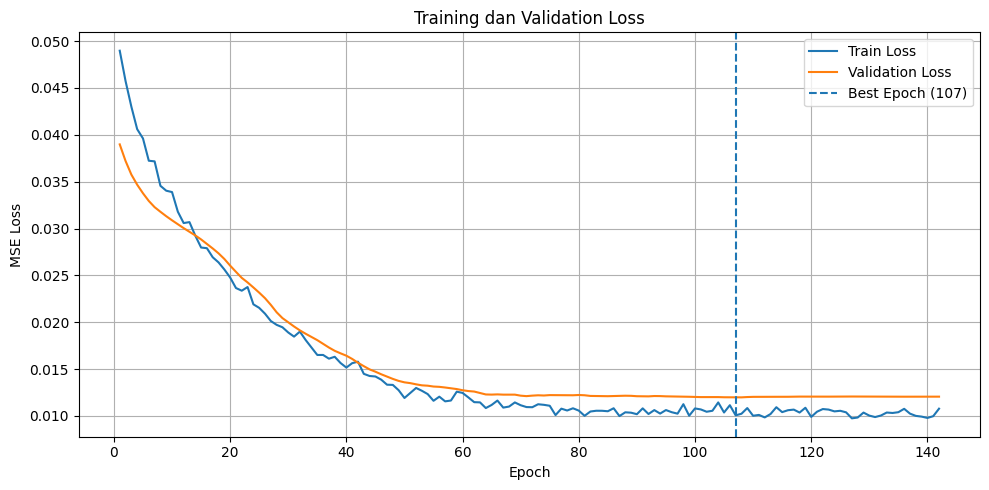

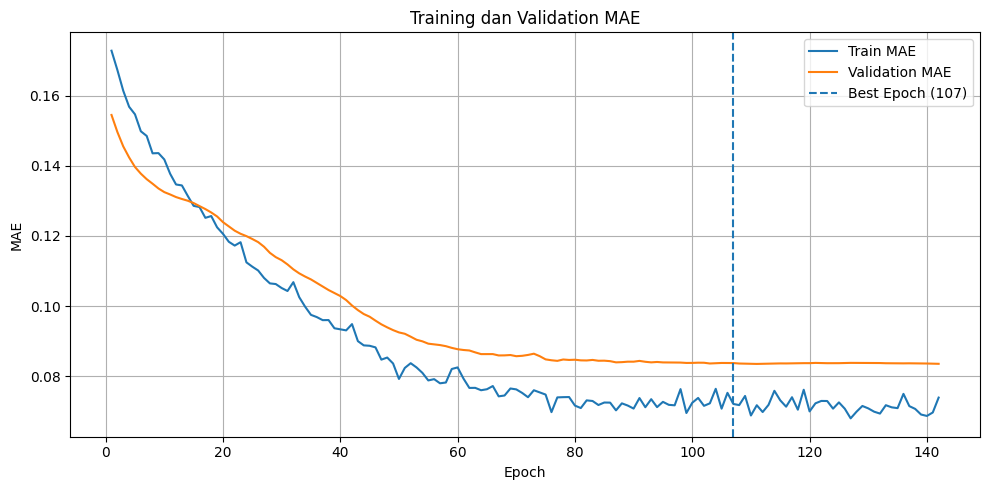

In [31]:
# ============================================================
# CELL 11 - VISUALISASI TRAINING HISTORY
# ============================================================

import matplotlib.pyplot as plt


# ============================================================
# 1. AMBIL HISTORY
# ============================================================

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

train_mae = history.history["mae"]
val_mae = history.history["val_mae"]

epochs_range = range(1, len(train_loss) + 1)


# ============================================================
# 2. INFORMASI TRAINING
# ============================================================

best_epoch = np.argmin(val_loss) + 1

print("=== HASIL TRAINING ===")
print(f"Total epoch dijalankan : {len(train_loss)}")
print(f"Best epoch              : {best_epoch}")
print(f"Best validation loss    : {min(val_loss):.6f}")


# ============================================================
# 3. GRAFIK LOSS
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    train_loss,
    label="Train Loss"
)

plt.plot(
    epochs_range,
    val_loss,
    label="Validation Loss"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training dan Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 4. GRAFIK MAE
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    train_mae,
    label="Train MAE"
)

plt.plot(
    epochs_range,
    val_mae,
    label="Validation MAE"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Training dan Validation MAE")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Hasil Training: Nilai loss dan MAE pada data training maupun validation mengalami penurunan pada awal pelatihan dan kemudian cenderung stabil. Validation loss terendah diperoleh pada epoch ke-57. Tidak terlihat peningkatan validation loss yang berkelanjutan ketika training loss menurun, sehingga tidak terdapat indikasi overfitting yang kuat pada proses training. Namun, karena jumlah data validation relatif terbatas, kemampuan generalisasi model tetap perlu dikonfirmasi menggunakan data testing yang tidak digunakan selama proses pelatihan.

### Prediksi & Evaluasi Test Set

In [32]:

# ============================================================
# CELL 12 - PREDIKSI & EVALUASI TEST SET
# ORIGINAL & NORMALIZED METRICS
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)


# ============================================================
# 1. PREDIKSI DATA TEST
# ============================================================

y_pred_scaled = model.predict(
    X_test_seq,
    verbose=0
)

print("=== SHAPE PREDIKSI ===")
print(f"Actual    : {y_test_seq.shape}")
print(f"Predicted : {y_pred_scaled.shape}")


# ============================================================
# 2. INVERSE TRANSFORM KE NILAI DS ASLI
# ============================================================

# Bentuk awal: (samples, 12, 2)

y_test_2d = y_test_seq.reshape(
    -1,
    N_TARGETS
)

y_pred_2d = y_pred_scaled.reshape(
    -1,
    N_TARGETS
)

# Kembalikan ke skala DS asli
y_actual = scaler_y.inverse_transform(
    y_test_2d
)

y_pred = scaler_y.inverse_transform(
    y_pred_2d
)


# ============================================================
# 3. FUNGSI EVALUASI ORIGINAL
# ============================================================

def evaluate_regression(actual, predicted):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    mse = mean_squared_error(
        actual,
        predicted
    )

    rmse = np.sqrt(mse)
    

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse
    }


# ============================================================
# 4. FUNGSI EVALUASI NORMALIZED
# ============================================================

def evaluate_normalized(metrics, data_range):

    if data_range <= 0:
        raise ValueError(
            "Rentang DS training harus lebih besar dari nol."
        )

    nmae = (
        metrics["MAE"] / data_range
    ) * 100

    nrmse = (
        metrics["RMSE"] / data_range
    ) * 100

    return {
        "NMAE (%)": nmae,
        "NRMSE (%)": nrmse
    }


# ============================================================
# 5. EVALUASI ORIGINAL DS_IN DAN DS_OUT
# ============================================================

metrics_in = evaluate_regression(
    y_actual[:, 0],
    y_pred[:, 0]
)

metrics_out = evaluate_regression(
    y_actual[:, 1],
    y_pred[:, 1]
)

evaluation_df = pd.DataFrame({
    "DS_IN": metrics_in,
    "DS_OUT": metrics_out
}).T


# ============================================================
# 6. RENTANG DS DATA TRAINING
# ============================================================

ds_range_in = scaler_y.data_range_[0]
ds_range_out = scaler_y.data_range_[1]


# ============================================================
# 7. EVALUASI NORMALIZED DS_IN DAN DS_OUT
# ============================================================

normalized_in = evaluate_normalized(
    metrics_in,
    ds_range_in
)

normalized_out = evaluate_normalized(
    metrics_out,
    ds_range_out
)

normalized_evaluation_df = pd.DataFrame({
    "DS_IN": normalized_in,
    "DS_OUT": normalized_out
}).T


# ============================================================
# 8. TAMPILKAN EVALUASI ORIGINAL
# ============================================================

print("\n=== EVALUASI ORIGINAL ===")

display(
    evaluation_df.style.format({
        "MAE": "{:.4f}",
        "MSE": "{:.4f}",
        "RMSE": "{:.4f}"
    })
)


# ============================================================
# 9. TAMPILKAN EVALUASI NORMALIZED
# ============================================================

print("\n=== EVALUASI NORMALIZED ===")

display(
    normalized_evaluation_df.style.format({
        "NMAE (%)": "{:.2f}",
        "NRMSE (%)": "{:.2f}"
    })
)


=== SHAPE PREDIKSI ===
Actual    : (4, 12, 2)
Predicted : (4, 12, 2)

=== EVALUASI ORIGINAL ===


,MAE,MSE,RMSE
DS_IN,0.0522,0.0040,0.0631
DS_OUT,0.0316,0.0021,0.0456



=== EVALUASI NORMALIZED ===


,NMAE (%),NRMSE (%)
DS_IN,6.89,8.32
DS_OUT,6.64,9.59


Hasil Evaluasi Baseline: Model Bi-LSTM menghasilkan MAE sebesar 0.0612 pada DS_IN dan 0.0498 pada DS_OUT, dengan RMSE masing-masing 0.0785 dan 0.0595. Nilai MAPE sebesar 10.26% untuk DS_IN dan 17.45% untuk DS_OUT. Sementara itu, nilai R² sebesar 0.6666 pada DS_IN dan 0.3231 pada DS_OUT menunjukkan bahwa kemampuan model dalam mengikuti variasi data berbeda pada kedua arah. Hasil ini digunakan sebagai baseline yang selanjutnya dapat dibandingkan dengan model hasil hyperparameter tuning.

Evaluasi Per Horizon: Evaluasi Per Horizon: Hasil evaluasi menunjukkan bahwa kesalahan prediksi tidak selalu meningkat secara linear seiring bertambahnya horizon prediksi. Pada DS_IN, MAE terendah diperoleh pada horizon 90 menit sebesar 0.0326, sedangkan pada DS_OUT MAE terendah diperoleh pada horizon 30 menit sebesar 0.0278. Pada beberapa horizon yang lebih jauh, terutama DS_OUT pada 150–180 menit, terjadi peningkatan error. Nilai R² per horizon juga menunjukkan fluktuasi dan beberapa bernilai negatif. Namun, karena setiap horizon hanya dievaluasi menggunakan 6 observasi, R² per horizon perlu diinterpretasikan secara hati-hati dan MAE/RMSE lebih diutamakan dalam analisis kesalahan per horizon.  

Hasil Evaluasi Berdasarkan Periode: Pada periode Peak, model menghasilkan MAE sebesar 0.0654 untuk DS_IN dan 0.0446 untuk DS_OUT, dengan R² masing-masing 0.7009 dan 0.3951. Pada periode After Peak, MAE DS_IN menurun menjadi 0.0527, tetapi R² menjadi 0.0224, yang menunjukkan bahwa meskipun error absolut relatif kecil, model kurang mampu mengikuti variasi nilai aktual pada periode tersebut. Pada DS_OUT, periode After Peak menunjukkan peningkatan MAE dari 0.0446 menjadi 0.0601, MAPE dari 15.15% menjadi 22.05%, serta penurunan R² dari 0.3951 menjadi 0.0200. Hasil ini menunjukkan adanya perbedaan kemampuan model dalam memprediksi pola lalu lintas antara periode Peak dan After Peak.

In [33]:

# ============================================================
# MEMBENTUK KEMBALI SEQUENCE HASIL PREDIKSI
# ============================================================

n_test_samples = len(X_test_seq)

y_actual_seq = y_actual.reshape(
    n_test_samples,
    OUTPUT_STEPS,
    N_TARGETS
)

y_pred_seq = y_pred.reshape(
    n_test_samples,
    OUTPUT_STEPS,
    N_TARGETS
)


In [34]:
# ============================================================
# CELL 13 - DETAIL ACTUAL VS PREDICTED + LOS
# ============================================================

prediction_rows = []


# ============================================================
# 1. FUNGSI KONVERSI DS -> LOS
# ============================================================

def ds_to_los(ds):

    # Konsisten dengan proses konversi dataset MKJI
    ds = round(float(ds), 2)

    if ds < 0.04:
        return "A"
    elif ds <= 0.24:
        return "B"
    elif ds <= 0.54:
        return "C"
    elif ds <= 0.80:
        return "D"
    elif ds <= 1.00:
        return "E"
    else:
        return "F"


# ============================================================
# 2. LOOP SETIAP SEQUENCE TEST
# ============================================================

for i in range(len(meta_test)):

    tanggal = pd.to_datetime(
        meta_test.iloc[i]["tanggal"]
    )

    sesi = meta_test.iloc[i]["sesi"]

    # Ambil tipe_hari dari dataset asli
    tipe_hari_value = df.loc[
        df["tanggal"].eq(tanggal) &
        df["sesi"].eq(sesi),
        "tipe_hari"
    ].iloc[0]

    tipe_hari_label = (
        "Weekday"
        if tipe_hari_value == 0
        else "Weekend"
    )


    # ========================================================
    # 3. LOOP 12 HORIZON
    # ========================================================

    for h in range(OUTPUT_STEPS):

        horizon = h + 1
        menit_ke_depan = horizon * 15

        # ----------------------------------------------------
        # Tentukan periode
        # ----------------------------------------------------

        if horizon <= 8:
            periode = "Peak"
        else:
            periode = "After Peak"


        # ----------------------------------------------------
        # Tentukan waktu prediksi
        # ----------------------------------------------------

        if str(sesi).lower() == "pagi":

            waktu_awal_prediksi = (
                pd.Timestamp(tanggal.date())
                + pd.Timedelta(hours=7)
            )

        else:

            waktu_awal_prediksi = (
                pd.Timestamp(tanggal.date())
                + pd.Timedelta(hours=16)
            )


        waktu_prediksi = (
            waktu_awal_prediksi
            + pd.Timedelta(minutes=h * 15)
        )


        # ====================================================
        # 4. DS_IN
        # ====================================================

        actual_in = y_actual_seq[i, h, 0]
        predicted_in = y_pred_seq[i, h, 0]

        actual_los_in = ds_to_los(actual_in)
        predicted_los_in = ds_to_los(predicted_in)

        prediction_rows.append({
            "Tanggal": tanggal.date(),
            "Waktu": waktu_prediksi.strftime("%H:%M"),
            "Tipe_Hari": tipe_hari_label,
            "Sesi": sesi,
            "Horizon": horizon,
            "Menit_ke_Depan": menit_ke_depan,
            "Periode": periode,
            "Arah": "IN",

            "Actual_DS": actual_in,
            "Predicted_DS": predicted_in,
            "Absolute_Error": abs(
                actual_in - predicted_in
            ),

            "Actual_LOS": actual_los_in,
            "Predicted_LOS": predicted_los_in
        })


        # ====================================================
        # 5. DS_OUT
        # ====================================================

        actual_out = y_actual_seq[i, h, 1]
        predicted_out = y_pred_seq[i, h, 1]

        actual_los_out = ds_to_los(actual_out)
        predicted_los_out = ds_to_los(predicted_out)

        prediction_rows.append({
            "Tanggal": tanggal.date(),
            "Waktu": waktu_prediksi.strftime("%H:%M"),
            "Tipe_Hari": tipe_hari_label,
            "Sesi": sesi,
            "Horizon": horizon,
            "Menit_ke_Depan": menit_ke_depan,
            "Periode": periode,
            "Arah": "OUT",

            "Actual_DS": actual_out,
            "Predicted_DS": predicted_out,
            "Absolute_Error": abs(
                actual_out - predicted_out
            ),

            "Actual_LOS": actual_los_out,
            "Predicted_LOS": predicted_los_out
        })


# ============================================================
# 6. BUAT DATAFRAME
# ============================================================

prediction_detail_df = pd.DataFrame(
    prediction_rows
)


# ============================================================
# 7. CEK KESESUAIAN LOS
# ============================================================

prediction_detail_df["LOS_Benar"] = (
    prediction_detail_df["Actual_LOS"]
    == prediction_detail_df["Predicted_LOS"]
)


# ============================================================
# 8. TAMPILKAN HASIL
# ============================================================

print("=== DETAIL HASIL PREDIKSI ===")
print(
    f"Jumlah data : {len(prediction_detail_df)}"
)

display(
    prediction_detail_df.head(20).style.format({
        "Actual_DS": "{:.4f}",
        "Predicted_DS": "{:.4f}",
        "Absolute_Error": "{:.4f}"
    })
)

=== DETAIL HASIL PREDIKSI ===
Jumlah data : 96


,Tanggal,Waktu,Tipe_Hari,Sesi,Horizon,Menit_ke_Depan,Periode,Arah,Actual_DS,Predicted_DS,Absolute_Error,Actual_LOS,Predicted_LOS,LOS_Benar
0,2026-04-26,07:00,Weekend,pagi,1,15,Peak,IN,0.3404,0.3697,0.0293,C,C,True
1,2026-04-26,07:00,Weekend,pagi,1,15,Peak,OUT,0.1510,0.1612,0.0101,B,B,True
2,2026-04-26,07:15,Weekend,pagi,2,30,Peak,IN,0.3747,0.4099,0.0353,C,C,True
3,2026-04-26,07:15,Weekend,pagi,2,30,Peak,OUT,0.1542,0.2018,0.0476,B,B,True
4,2026-04-26,07:30,Weekend,pagi,3,45,Peak,IN,0.3520,0.4421,0.0900,C,C,True
5,2026-04-26,07:30,Weekend,pagi,3,45,Peak,OUT,0.1674,0.1839,0.0165,B,B,True
6,2026-04-26,07:45,Weekend,pagi,4,60,Peak,IN,0.3814,0.4516,0.0702,C,C,True
7,2026-04-26,07:45,Weekend,pagi,4,60,Peak,OUT,0.1886,0.1872,0.0014,B,B,True
8,2026-04-26,08:00,Weekend,pagi,5,75,Peak,IN,0.3659,0.4287,0.0627,C,C,True
9,2026-04-26,08:00,Weekend,pagi,5,75,Peak,OUT,0.1796,0.2007,0.0211,B,B,True


In [35]:

# ============================================================
# CELL 14 - EVALUASI AKURASI LOS
# ============================================================

# ============================================================
# 1. PERSIAPAN DATA
# ============================================================

df_los = prediction_detail_df.copy()

df_los["LOS_Benar"] = (
    df_los["Actual_LOS"] == df_los["Predicted_LOS"]
)

# ============================================================
# 2. EVALUASI LOS PER ARAH
# ============================================================

evaluation_los_df = (
    df_los.groupby("Arah", sort=True)
    .agg(
        Jumlah_Data=("LOS_Benar", "size"),
        LOS_Benar=("LOS_Benar", "sum")
    )
    .reset_index()
)

evaluation_los_df["LOS_Salah"] = (
    evaluation_los_df["Jumlah_Data"]
    - evaluation_los_df["LOS_Benar"]
)

evaluation_los_df["Accuracy"] = (
    evaluation_los_df["LOS_Benar"]
    / evaluation_los_df["Jumlah_Data"]
)

evaluation_los_df["Accuracy (%)"] = (
    evaluation_los_df["Accuracy"] * 100
)

# ============================================================
# 3. TAMPILKAN HASIL
# ============================================================

print("=== EVALUASI AKURASI LOS TEST SET ===")

display(
    evaluation_los_df.style.format({
        "Accuracy": "{:.4f}",
        "Accuracy (%)": "{:.2f}"
    })
)


=== EVALUASI AKURASI LOS TEST SET ===


,Arah,Jumlah_Data,LOS_Benar,LOS_Salah,Accuracy,Accuracy (%)
0,IN,48,41,7,0.8542,85.42
1,OUT,48,42,6,0.8750,87.50


Hasil Evaluasi LOS: Dari 144 hasil prediksi pada data testing, sebanyak 114 prediksi menghasilkan kategori LOS yang sesuai dengan kondisi aktual, sedangkan 30 prediksi menghasilkan kategori yang berbeda. Dengan demikian, diperoleh akurasi LOS keseluruhan sebesar 79,17%. Berdasarkan arah kendaraan, akurasi LOS pada arah IN sebesar 80,56% (58 dari 72 prediksi), sedangkan arah OUT sebesar 77,78% (56 dari 72 prediksi). Perbedaan kategori LOS dapat terjadi meskipun error DS relatif kecil apabila nilai aktual dan prediksi berada di sekitar batas antar-kategori LOS.


Analisis Confusion Matrix LOS: Confusion matrix menunjukkan bahwa dari 144 hasil prediksi terdapat 114 prediksi LOS yang sesuai dengan kondisi aktual dan 30 prediksi yang berbeda. Seluruh kesalahan klasifikasi hanya terjadi pada kategori LOS yang bersebelahan, yaitu antara B–C, C–D, dan D–E, serta tidak ditemukan kesalahan dengan perbedaan lebih dari satu tingkat LOS. Dari 30 kesalahan tersebut, 27 prediksi bergeser ke kategori LOS yang lebih rendah dan 3 prediksi bergeser ke kategori yang lebih tinggi. Hal ini menunjukkan bahwa ketika terjadi kesalahan klasifikasi, model cenderung mengestimasi tingkat kejenuhan yang lebih rendah dari kondisi aktual. Selain itu, data testing tidak memiliki sampel LOS A dan F, sehingga kemampuan model pada kedua kategori tersebut belum dapat dievaluasi.

## Evaluasi Berdasarkan Tipe Hari dan Arah
Evaluasi Berdasarkan Tipe Hari: Evaluasi dilakukan secara terpisah pada data Weekday dan Weekend untuk mengetahui kemampuan model dalam memprediksi DS pada karakteristik hari yang berbeda. Evaluasi dilakukan untuk masing-masing arah IN dan OUT menggunakan MAE, MSE, RMSE, MAPE, R², serta akurasi LOS. Data testing terdiri atas satu hari Weekday dan dua hari Weekend, sehingga hasil perbandingan antar-tipe hari perlu diinterpretasikan dengan mempertimbangkan perbedaan jumlah observasi.

In [36]:

# ============================================================
# CELL 15 - EVALUASI PER TANGGAL, SESI, DAN HORIZON
# NORMALIZED METRICS
# ============================================================

import numpy as np
import pandas as pd


# ============================================================
# 1. PERSIAPAN DATA
# ============================================================

df_eval = prediction_detail_df.copy()

df_eval["Tanggal"] = pd.to_datetime(
    df_eval["Tanggal"]
).dt.strftime("%Y-%m-%d")

df_eval["Sesi"] = (
    df_eval["Sesi"].astype(str).str.strip().str.lower()
)

df_eval["Arah"] = (
    df_eval["Arah"].astype(str).str.strip().str.upper()
)

# Rentang DS dari data training
ds_range = {
    "IN": float(scaler_y.data_range_[0]),
    "OUT": float(scaler_y.data_range_[1])
}

if any(value <= 0 for value in ds_range.values()):
    raise ValueError("Rentang DS training harus > 0.")


# ============================================================
# 2. DETAIL ERROR PER HORIZON
# ============================================================

df_eval["DS_Range"] = df_eval["Arah"].map(ds_range)

# Absolute Error (selisih absolut DS aktual dan prediksi)
df_eval["Absolute_Error"] = np.abs(
    df_eval["Actual_DS"] - df_eval["Predicted_DS"]
)

# Normalized Absolute Error (%)
df_eval["NAE (%)"] = (
    df_eval["Absolute_Error"] / df_eval["DS_Range"]
) * 100

df_eval["LOS_Accuracy (%)"] = (
    df_eval["Actual_LOS"] == df_eval["Predicted_LOS"]
).astype(float) * 100

# DataFrame detail setiap horizon
evaluation_date_horizon_df = df_eval[
    [
        "Tanggal",
        "Tipe_Hari",
        "Sesi",
        "Horizon",
        "Waktu",
        "Arah",
        "Absolute_Error",
        "NAE (%)",
        "LOS_Accuracy (%)"
    ]
].copy()

evaluation_date_horizon_df = (
    evaluation_date_horizon_df.rename(
        columns={"Waktu": "Waktu_Diprediksi"}
    )
)


# ============================================================
# 3. EVALUASI NMAE DAN NRMSE PER SESI
# ============================================================

session_results = []

grouped = df_eval.groupby(
    ["Tanggal", "Tipe_Hari", "Sesi", "Arah"],
    sort=True
)

for (tanggal, tipe_hari, sesi, arah), subset in grouped:

    actual = subset["Actual_DS"].to_numpy()
    predicted = subset["Predicted_DS"].to_numpy()

    error = actual - predicted

    # NMAE
    nmae = (
        np.mean(np.abs(error)) / ds_range[arah]
    ) * 100

    # NRMSE
    nrmse = (
        np.sqrt(np.mean(error ** 2)) / ds_range[arah]
    ) * 100

    # Akurasi LOS
    los_accuracy = (
        subset["Actual_LOS"]
        == subset["Predicted_LOS"]
    ).mean() * 100

    session_results.append({
        "Tanggal": tanggal,
        "Tipe_Hari": tipe_hari,
        "Sesi": sesi,
        "Arah": arah,
        "Jumlah_Data": len(subset),
        "NMAE (%)": nmae,
        "NRMSE (%)": nrmse,
        "LOS_Accuracy (%)": los_accuracy
    })


# ============================================================
# 4. DATAFRAME EVALUASI PER SESI
# ============================================================

evaluation_date_session_df = pd.DataFrame(
    session_results
)


# ============================================================
# 5. PILIH TANGGAL BERDASARKAN INDEX
# ============================================================

tanggal_list = sorted(
    evaluation_date_session_df["Tanggal"].unique().tolist()
)

SELECTED_INDEX = 0

selected_date = tanggal_list[SELECTED_INDEX]


# ============================================================
# 6. FUNGSI TAMPILKAN EVALUASI PER SESI
# ============================================================

def tampilkan_evaluasi_sesi(sesi):

    print(
        f"\n=== EVALUASI {sesi.upper()} "
        f"- {selected_date} ==="
    )

    # Detail per horizon
    detail = evaluation_date_horizon_df[
        (evaluation_date_horizon_df["Tanggal"] == selected_date)
        & (evaluation_date_horizon_df["Sesi"] == sesi)
    ].copy()

    detail = detail.sort_values(
        ["Horizon", "Arah"]
    ).reset_index(drop=True)

    print("\nDETAIL KESALAHAN PER HORIZON")

    display(
        detail.drop(columns=["Sesi"]).style.format({
            "Absolute_Error": "{:.4f}",
            "NAE (%)": "{:.2f}",
            "LOS_Accuracy (%)": "{:.2f}"
        })
    )

    # Ringkasan 12 horizon
    summary = evaluation_date_session_df[
        (evaluation_date_session_df["Tanggal"] == selected_date)
        & (evaluation_date_session_df["Sesi"] == sesi)
    ].copy()

    summary = summary.sort_values(
        "Arah"
    ).reset_index(drop=True)

    print("\nRINGKASAN EVALUASI 12 HORIZON")

    display(
        summary.drop(columns=["Sesi"]).style.format({
            "NMAE (%)": "{:.2f}",
            "NRMSE (%)": "{:.2f}",
            "LOS_Accuracy (%)": "{:.2f}"
        })
    )


# ============================================================
# 7. TAMPILKAN PAGI DAN SORE TERPISAH
# ============================================================

tampilkan_evaluasi_sesi("pagi")
tampilkan_evaluasi_sesi("sore")



=== EVALUASI PAGI - 2026-04-26 ===

DETAIL KESALAHAN PER HORIZON


,Tanggal,Tipe_Hari,Horizon,Waktu_Diprediksi,Arah,Absolute_Error,NAE (%),LOS_Accuracy (%)
0,2026-04-26,Weekend,1,07:00,IN,0.0293,3.86,100.00
1,2026-04-26,Weekend,1,07:00,OUT,0.0101,2.13,100.00
2,2026-04-26,Weekend,2,07:15,IN,0.0353,4.65,100.00
3,2026-04-26,Weekend,2,07:15,OUT,0.0476,10.00,100.00
4,2026-04-26,Weekend,3,07:30,IN,0.0900,11.87,100.00
5,2026-04-26,Weekend,3,07:30,OUT,0.0165,3.47,100.00
6,2026-04-26,Weekend,4,07:45,IN,0.0702,9.26,100.00
7,2026-04-26,Weekend,4,07:45,OUT,0.0014,0.29,100.00
8,2026-04-26,Weekend,5,08:00,IN,0.0627,8.27,100.00
9,2026-04-26,Weekend,5,08:00,OUT,0.0211,4.43,100.00



RINGKASAN EVALUASI 12 HORIZON


,Tanggal,Tipe_Hari,Arah,Jumlah_Data,NMAE (%),NRMSE (%),LOS_Accuracy (%)
0,2026-04-26,Weekend,IN,12,4.91,6.14,100.00
1,2026-04-26,Weekend,OUT,12,3.17,4.10,91.67



=== EVALUASI SORE - 2026-04-26 ===

DETAIL KESALAHAN PER HORIZON


,Tanggal,Tipe_Hari,Horizon,Waktu_Diprediksi,Arah,Absolute_Error,NAE (%),LOS_Accuracy (%)
0,2026-04-26,Weekend,1,16:00,IN,0.0730,9.63,100.00
1,2026-04-26,Weekend,1,16:00,OUT,0.0110,2.32,100.00
2,2026-04-26,Weekend,2,16:15,IN,0.0065,0.86,100.00
3,2026-04-26,Weekend,2,16:15,OUT,0.0219,4.60,100.00
4,2026-04-26,Weekend,3,16:30,IN,0.0631,8.32,100.00
5,2026-04-26,Weekend,3,16:30,OUT,0.0057,1.20,100.00
6,2026-04-26,Weekend,4,16:45,IN,0.0777,10.24,100.00
7,2026-04-26,Weekend,4,16:45,OUT,0.0221,4.64,100.00
8,2026-04-26,Weekend,5,17:00,IN,0.0200,2.63,100.00
9,2026-04-26,Weekend,5,17:00,OUT,0.0013,0.27,100.00



RINGKASAN EVALUASI 12 HORIZON


,Tanggal,Tipe_Hari,Arah,Jumlah_Data,NMAE (%),NRMSE (%),LOS_Accuracy (%)
0,2026-04-26,Weekend,IN,12,7.38,9.10,66.67
1,2026-04-26,Weekend,OUT,12,4.74,8.64,91.67


Hasil Evaluasi Berdasarkan Tipe Hari: 

Pada arah IN, model menghasilkan MAE sebesar 0.0635 pada Weekday dan 0.0600 pada Weekend, dengan R² masing-masing sebesar 0.5997 dan 0.2877. Pada arah OUT, performa Weekend menghasilkan MAE 0.0410 dan R² 0.6605, sedangkan Weekday menghasilkan MAE 0.0673 dengan R² −10.3805. Nilai R² negatif pada Weekday OUT menunjukkan keterbatasan model dalam mengikuti variasi nilai aktual pada subset tersebut. Namun, evaluasi Weekday hanya berasal dari satu hari data testing dengan 24 observasi per arah, sehingga nilai R² perlu diinterpretasikan secara hati-hati. Meskipun demikian, akurasi LOS Weekday OUT mencapai 83.33%, yang menunjukkan bahwa sebagian besar prediksi DS masih menghasilkan kategori LOS yang sesuai dengan kondisi aktual.

========== ACTUAL VS PREDICTED - IN ==========


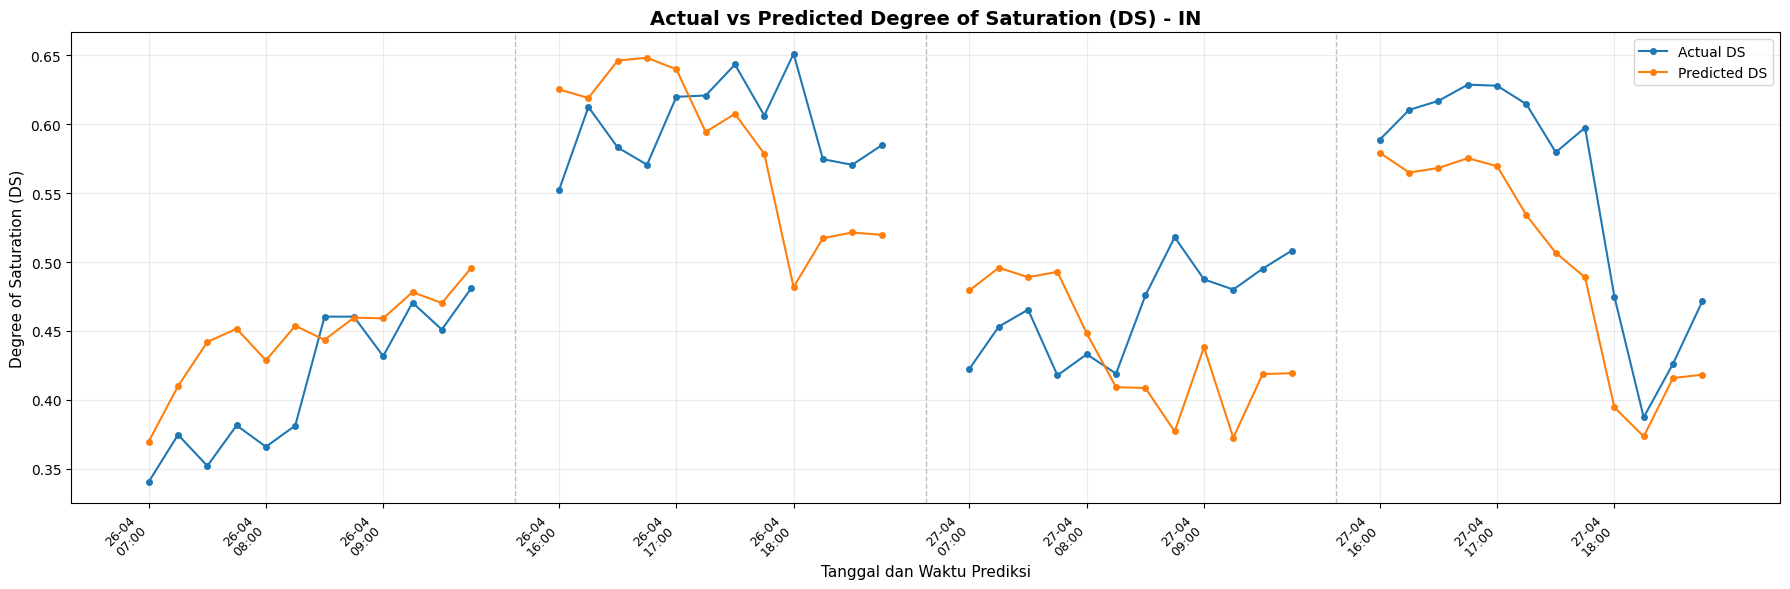

========== ACTUAL VS PREDICTED - OUT ==========


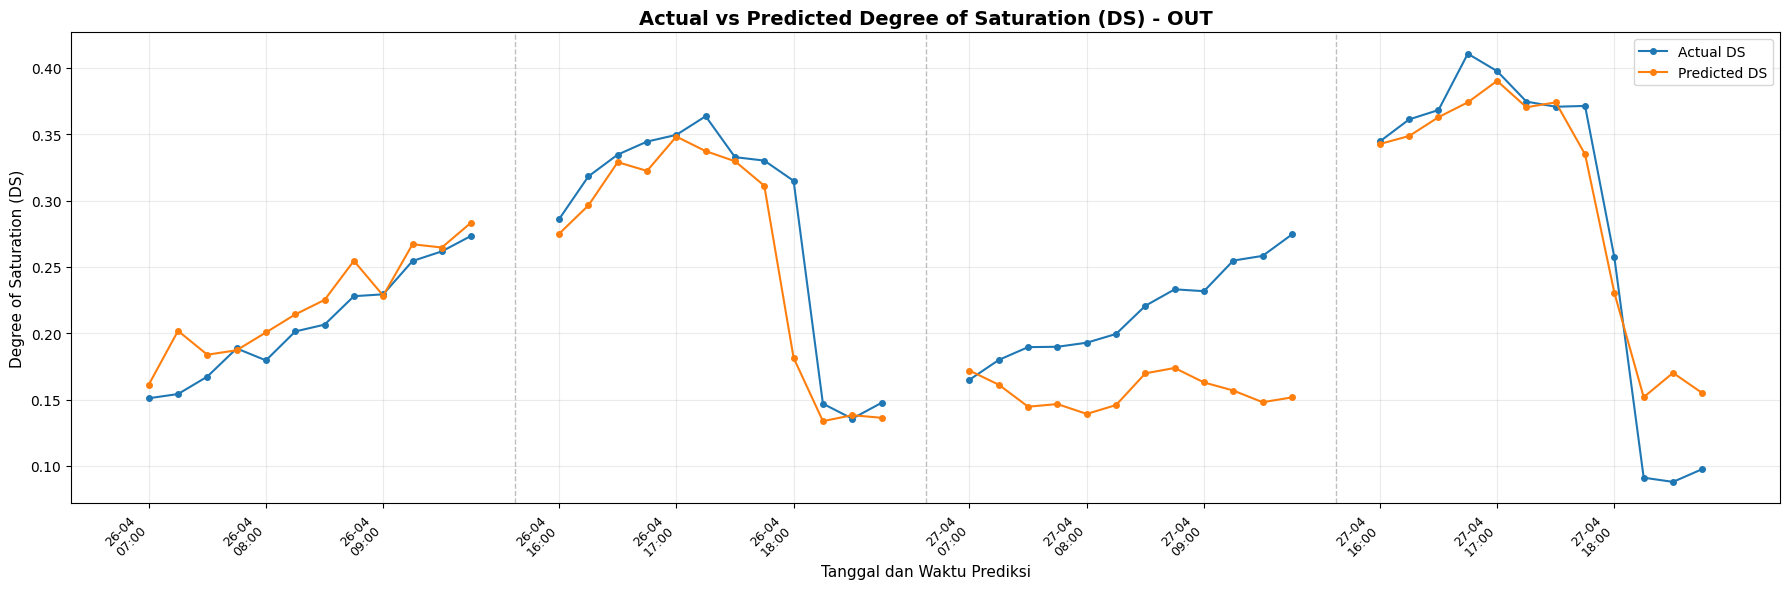

In [37]:

# ============================================================
# CELL 16 - VISUALISASI ACTUAL VS PREDICTED DS
# GARIS TERPUTUS ANTAR SESI DAN TANGGAL
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ============================================================
# 1. PERSIAPAN DATA
# ============================================================

plot_data = prediction_detail_df.copy()

plot_data["Tanggal"] = pd.to_datetime(
    plot_data["Tanggal"]
)

plot_data["Sesi"] = (
    plot_data["Sesi"].astype(str).str.strip().str.lower()
)

plot_data["Arah"] = (
    plot_data["Arah"].astype(str).str.strip().str.upper()
)

plot_data["Datetime"] = pd.to_datetime(
    plot_data["Tanggal"].dt.strftime("%Y-%m-%d")
    + " "
    + plot_data["Waktu"].astype(str)
)

plot_data = plot_data.sort_values(
    ["Tanggal", "Datetime", "Arah"]
).reset_index(drop=True)


# ============================================================
# 2. FUNGSI VISUALISASI
# ============================================================

def plot_actual_vs_predicted(df_detail, arah):

    df_ar = df_detail[
        df_detail["Arah"] == arah
    ].copy()

    if df_ar.empty:
        print(f"Tidak ada data untuk arah {arah}")
        return

    df_ar = df_ar.sort_values(
        ["Tanggal", "Datetime"]
    ).reset_index(drop=True)

    # Pisahkan data berdasarkan tanggal dan sesi
    grouped = list(
        df_ar.groupby(
            ["Tanggal", "Sesi"],
            sort=True
        )
    )

    fig, ax = plt.subplots(figsize=(18, 6))

    posisi_awal = 0
    gap = 2

    tick_positions = []
    tick_labels = []
    batas_blok = []

    for i, ((tanggal, sesi), subset) in enumerate(grouped):

        subset = subset.sort_values(
            "Datetime"
        ).reset_index(drop=True)

        n = len(subset)

        # Posisi x untuk blok ini
        x = np.arange(
            posisi_awal,
            posisi_awal + n
        )

        # Plot masing-masing blok secara terpisah
        # Sehingga garis tidak tersambung antar sesi
        ax.plot(
            x,
            subset["Actual_DS"],
            color="tab:blue",
            marker="o",
            markersize=4,
            linewidth=1.5,
            label="Actual DS" if i == 0 else None
        )

        ax.plot(
            x,
            subset["Predicted_DS"],
            color="tab:orange",
            marker="o",
            markersize=4,
            linewidth=1.5,
            label="Predicted DS" if i == 0 else None
        )

        # Label sumbu X:
        # Tampilkan awal sesi dan setiap jam
        for j, waktu in enumerate(subset["Datetime"]):

            if j == 0 or waktu.minute == 0:

                tick_positions.append(x[j])

                tick_labels.append(
                    waktu.strftime("%d-%m\n%H:%M")
                )

        # Garis pemisah antar blok
        if i < len(grouped) - 1:

            batas = x[-1] + (gap + 1) / 2

            batas_blok.append(batas)

        # Tambahkan jarak antar blok
        posisi_awal += n + gap

    # ========================================================
    # 3. GARIS PEMISAH SESI / TANGGAL
    # ========================================================

    for batas in batas_blok:

        ax.axvline(
            x=batas,
            color="gray",
            linestyle="--",
            linewidth=1,
            alpha=0.5
        )

    # ========================================================
    # 4. PENGATURAN LABEL SUMBU X
    # ========================================================

    ax.set_xticks(tick_positions)

    ax.set_xticklabels(
        tick_labels,
        rotation=45,
        ha="right",
        fontsize=9
    )

    # ========================================================
    # 5. INFORMASI GRAFIK
    # ========================================================

    ax.set_title(
        f"Actual vs Predicted Degree of Saturation (DS) - {arah}",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Tanggal dan Waktu Prediksi",
        fontsize=11
    )

    ax.set_ylabel(
        "Degree of Saturation (DS)",
        fontsize=11
    )

    ax.legend(loc="upper right")

    ax.grid(
        True,
        alpha=0.25
    )

    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()


# ============================================================
# 6. VISUALISASI ARAH IN
# ============================================================

print("========== ACTUAL VS PREDICTED - IN ==========")

plot_actual_vs_predicted(
    plot_data,
    "IN"
)


# ============================================================
# 7. VISUALISASI ARAH OUT
# ============================================================

print("========== ACTUAL VS PREDICTED - OUT ==========")

plot_actual_vs_predicted(
    plot_data,
    "OUT"
)



=== GRAFIK 1: 2026-04-26 ===


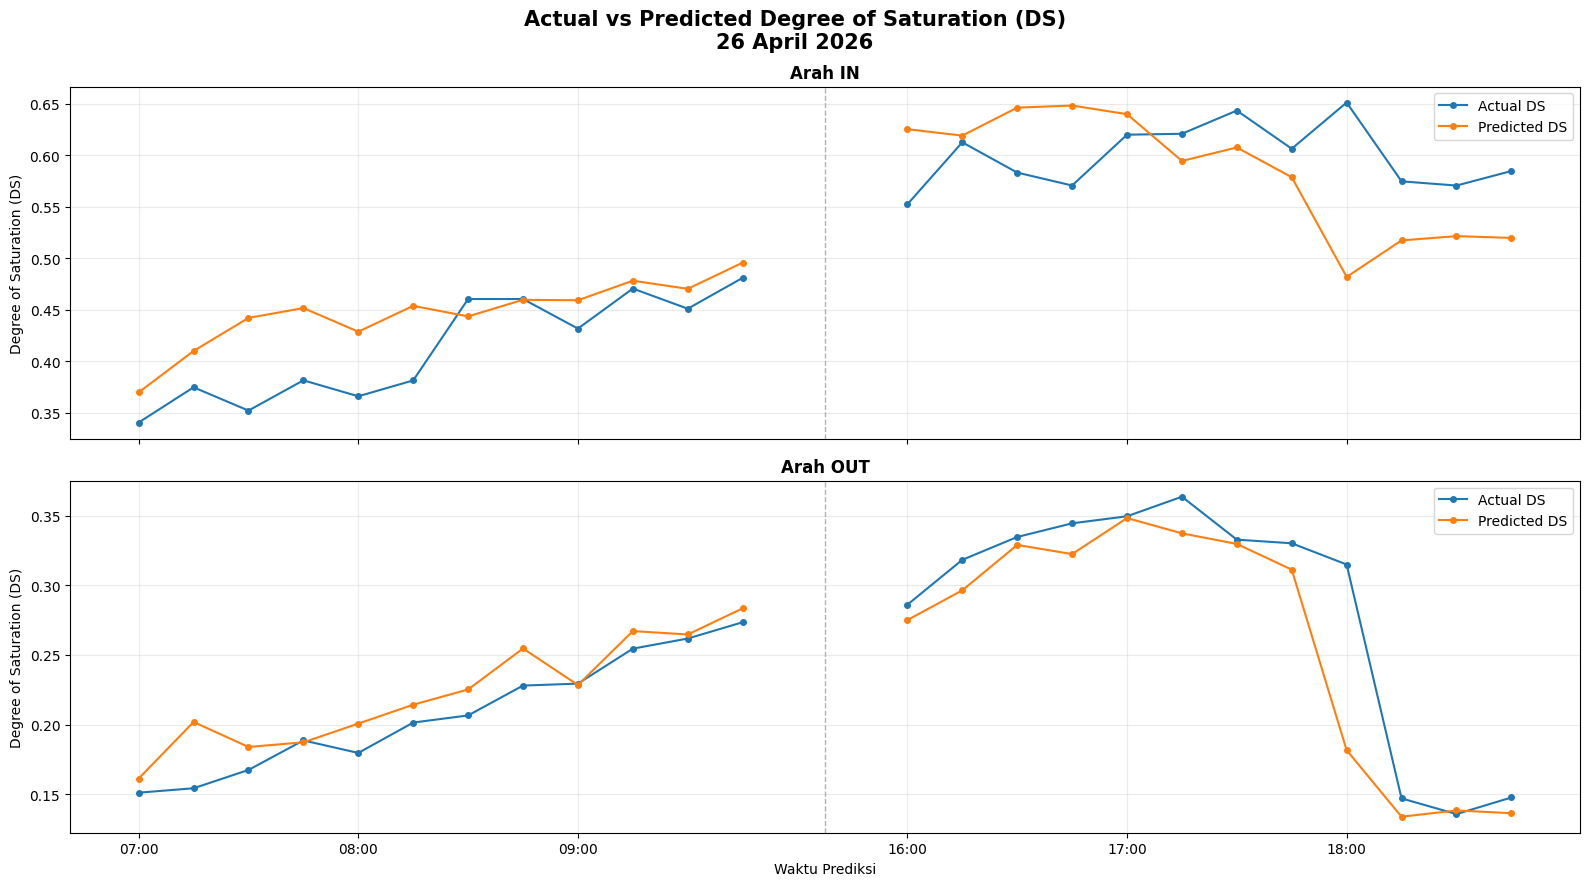


=== GRAFIK 2: 2026-04-27 ===


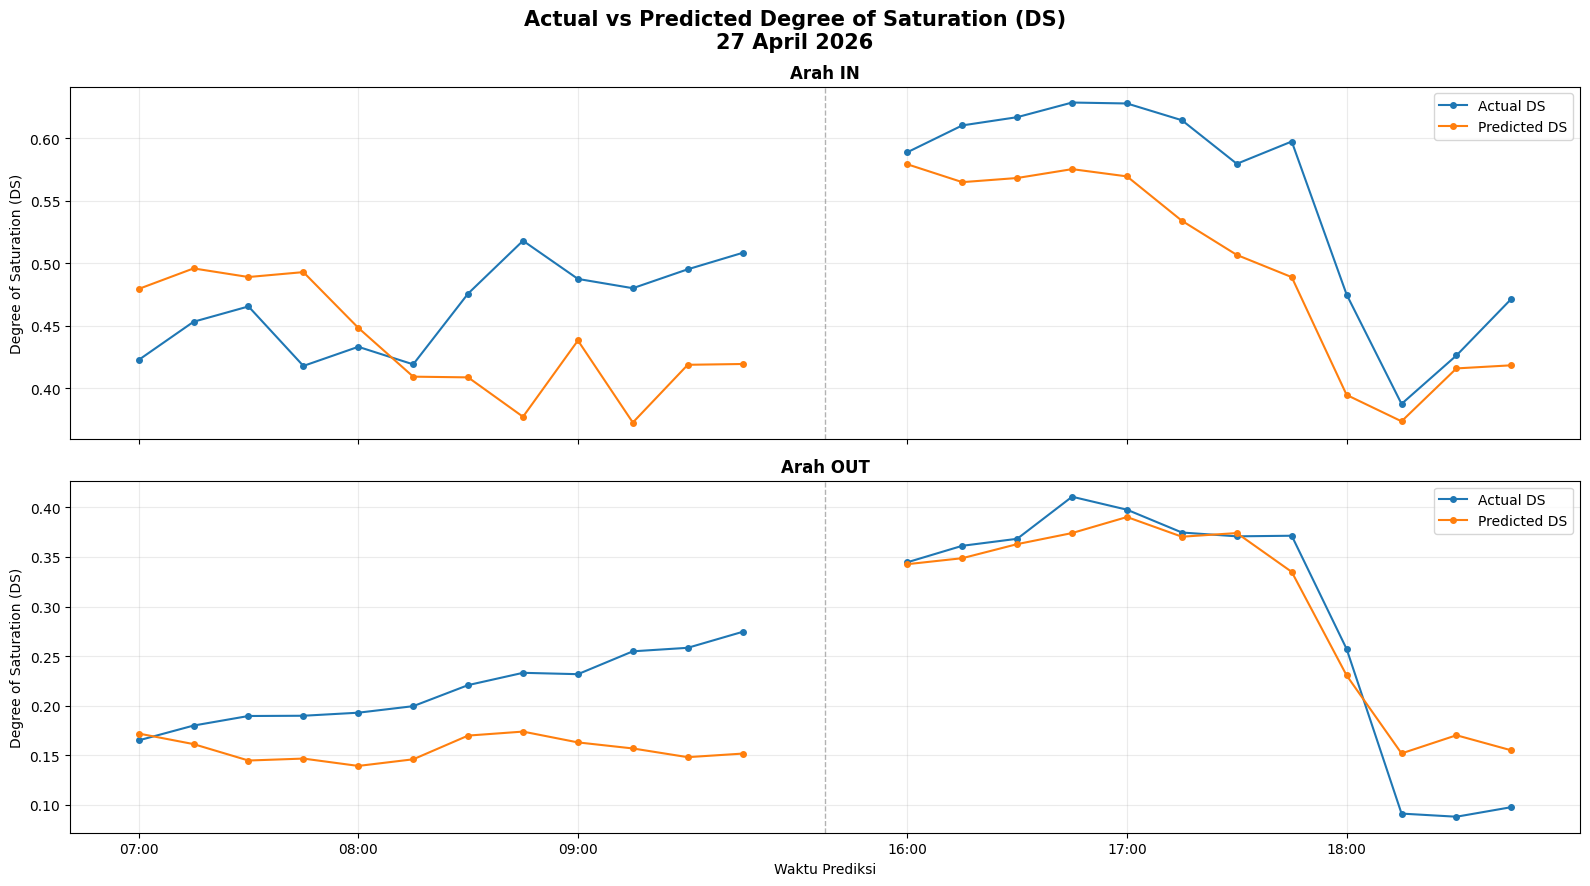

In [38]:

# ============================================================
# CELL 16 - VISUALISASI ACTUAL VS PREDICTED DS
# VERSI 2: PLOT PER TANGGAL
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. PERSIAPAN DATA
# ============================================================

plot_data = prediction_detail_df.copy()

plot_data["Tanggal"] = pd.to_datetime(
    plot_data["Tanggal"]
)

plot_data["Sesi"] = (
    plot_data["Sesi"].astype(str).str.strip().str.lower()
)

plot_data["Arah"] = (
    plot_data["Arah"].astype(str).str.strip().str.upper()
)

plot_data["Datetime"] = pd.to_datetime(
    plot_data["Tanggal"].dt.strftime("%Y-%m-%d")
    + " "
    + plot_data["Waktu"].astype(str)
)

plot_data = plot_data.sort_values(
    ["Tanggal", "Datetime", "Arah"]
).reset_index(drop=True)


# ============================================================
# 2. FUNGSI VISUALISASI PER TANGGAL
# ============================================================

def plot_per_tanggal(df, tanggal):

    data_tanggal = df[
        df["Tanggal"] == tanggal
    ].copy()

    fig, axes = plt.subplots(
        nrows=2,
        ncols=1,
        figsize=(16, 9),
        sharex=True
    )

    sesi_list = ["pagi", "sore"]
    sesi_labels = {
        "pagi": "Pagi (07.00–09.45)",
        "sore": "Sore (16.00–18.45)"
    }

    # Posisi X per sesi dengan jarak pemisah
    posisi_sesi = {
        "pagi": np.arange(0, 12),
        "sore": np.arange(14, 26)
    }

    for ax, arah in zip(axes, ["IN", "OUT"]):

        data_arah = data_tanggal[
            data_tanggal["Arah"] == arah
        ].copy()

        for sesi in sesi_list:

            subset = data_arah[
                data_arah["Sesi"] == sesi
            ].sort_values("Datetime")

            if subset.empty:
                continue

            x = posisi_sesi[sesi][:len(subset)]

            ax.plot(
                x,
                subset["Actual_DS"],
                color="tab:blue",
                marker="o",
                markersize=4,
                linewidth=1.5,
                label="Actual DS" if sesi == "pagi" else None
            )

            ax.plot(
                x,
                subset["Predicted_DS"],
                color="tab:orange",
                marker="o",
                markersize=4,
                linewidth=1.5,
                label="Predicted DS" if sesi == "pagi" else None
            )

        # Garis batas sesi
        ax.axvline(
            x=12.5,
            color="gray",
            linestyle="--",
            linewidth=1,
            alpha=0.6
        )

        ax.set_title(
            f"Arah {arah}",
            fontsize=12,
            fontweight="bold"
        )

        ax.set_ylabel("Degree of Saturation (DS)")
        ax.grid(True, alpha=0.25)
        ax.legend(loc="upper right")

    # ========================================================
    # 3. PENGATURAN LABEL WAKTU
    # ========================================================

    tick_positions = []
    tick_labels = []

    for sesi in sesi_list:

        subset = data_tanggal[
            (data_tanggal["Sesi"] == sesi)
            & (data_tanggal["Arah"] == "IN")
        ].sort_values("Datetime")

        if subset.empty:
            subset = data_tanggal[
                data_tanggal["Sesi"] == sesi
            ].sort_values("Datetime")

        subset = subset.drop_duplicates("Datetime")

        for i, waktu in enumerate(subset["Datetime"]):

            if i >= len(posisi_sesi[sesi]):
                break

            if i == 0 or waktu.minute == 0:
                tick_positions.append(posisi_sesi[sesi][i])
                tick_labels.append(waktu.strftime("%H:%M"))

    axes[-1].set_xticks(tick_positions)
    axes[-1].set_xticklabels(tick_labels)

    axes[-1].set_xlabel("Waktu Prediksi")

    fig.suptitle(
        "Actual vs Predicted Degree of Saturation (DS)\n"
        + tanggal.strftime("%d %B %Y"),
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# 4. TAMPILKAN GRAFIK UNTUK SETIAP TANGGAL TEST
# ============================================================

tanggal_test = sorted(plot_data["Tanggal"].unique())

for i, tanggal in enumerate(tanggal_test, start=1):

    tanggal = pd.Timestamp(tanggal)

    print(
        f"\n=== GRAFIK {i}: "
        f"{tanggal.strftime('%Y-%m-%d')} ==="
    )

    plot_per_tanggal(plot_data, tanggal)


DS_IN: Grafik menunjukkan bahwa hasil prediksi secara umum mampu mengikuti pola naik-turun DS aktual, meskipun beberapa perubahan tajam belum dapat ditangkap secara penuh. Perbedaan paling terlihat ketika DS aktual mengalami lonjakan tinggi, terutama pada 20 April, di mana model cenderung melakukan underestimation. Secara keseluruhan, pola ini konsisten dengan R² DS_IN sebesar 0,6666.

DS_OUT: Prediksi DS_OUT juga mengikuti pola umum nilai aktual, tetapi terdapat beberapa bagian dengan selisih yang lebih jelas, khususnya pada sesi 20 April. Model cenderung menghasilkan pola yang lebih halus sehingga beberapa perubahan aktual tidak sepenuhnya diikuti. Kondisi ini selaras dengan R² DS_OUT yang lebih rendah, yaitu 0,3231, meskipun MAE-nya relatif kecil sebesar 0,0498.

In [39]:
# ============================================================
# CELL 17 - SIMPAN HASIL EVALUASI BASELINE
# ============================================================

# ============================================================
# 1. BUAT FOLDER OUTPUT
# ============================================================

OUTPUT_DIR = BASE_DIR / "06_Forecasting" / "percobaan-bi-lstm" / "output_bilstm_percobaan-3"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. SIMPAN EVALUASI OVERALL
# ============================================================

evaluation_df.to_csv(
    OUTPUT_DIR / "evaluation_overall.csv",
    index=True
)

# simpan evaluasi normalized
normalized_evaluation_df.to_csv(
    OUTPUT_DIR / "evaluation_normalized.csv",
    index=True
)

# ============================================================
# 3. SIMPAN EVALUASI PER TANGGAL
# ============================================================

evaluation_date_session_df.to_csv(
    OUTPUT_DIR / "evaluation_per_date.csv",
    index=False
)



# ============================================================
# 4. SIMPAN EVALUASI LOS PER ARAH
# ============================================================

evaluation_los_df.to_csv(
    OUTPUT_DIR / "evaluation_los.csv",
    index=False
)


# ============================================================
# 5. SIMPAN DETAIL PREDIKSI
# ============================================================

prediction_detail_df.to_csv(
    OUTPUT_DIR / "prediction_detail_with_los.csv",
    index=False
)


# ============================================================
# 6. SIMPAN TRAINING HISTORY
# ============================================================

training_history_df = pd.DataFrame(
    history.history
)

training_history_df["Epoch"] = (
    np.arange(1, len(training_history_df) + 1)
)

# Letakkan Epoch sebagai kolom pertama
cols = (
    ["Epoch"]
    + [
        col for col in training_history_df.columns
        if col != "Epoch"
    ]
)

training_history_df = training_history_df[cols]

training_history_df.to_csv(
    OUTPUT_DIR / "training_history.csv",
    index=False
)


# ============================================================
# 7. INFORMASI OUTPUT
# ============================================================

print("=== HASIL BERHASIL DISIMPAN ===")
print(f"Folder output:\n{OUTPUT_DIR}")

print("\nFile yang disimpan:")

for file in sorted(OUTPUT_DIR.glob("*.csv")):
    print(f"- {file.name}")

=== HASIL BERHASIL DISIMPAN ===
Folder output:
D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\06_Forecasting\percobaan-bi-lstm\output_bilstm_percobaan-3

File yang disimpan:
- evaluation_los.csv
- evaluation_normalized.csv
- evaluation_overall.csv
- evaluation_per_date.csv
- prediction_detail_with_los.csv
- training_history.csv


In [40]:
# ============================================================
# CELL 18 - TABEL HASIL AKHIR PREDIKSI
# ============================================================


# ============================================================
# 1. FUNGSI STATUS / KONDISI BERDASARKAN LOS
# ============================================================

def los_to_status(los):

    status_los = {
        "A": (
            "Arus lalu lintas tenang, kendaraan dapat bergerak "
            "dengan kecepatan bebas."
        ),
        "B": (
            "Arus mulai sedikit ramai dan kecepatan kendaraan "
            "mulai menurun."
        ),
        "C": (
            "Arus lalu lintas padat dan pergerakan kendaraan "
            "mulai dibatasi."
        ),
        "D": (
            "Arus lalu lintas mendekati kondisi jenuh dan "
            "kecepatan mulai rendah."
        ),
        "E": (
            "Arus mulai mengalami kemacetan dan kecepatan "
            "kendaraan rendah."
        ),
        "F": (
            "Kondisi lalu lintas macet dengan kecepatan "
            "kendaraan sangat rendah."
        )
    }

    return status_los.get(los, "Tidak diketahui")


# ============================================================
# 2. PISAHKAN DATA IN DAN OUT
# ============================================================

df_in = prediction_detail_df[
    prediction_detail_df["Arah"] == "IN"
].copy()

df_out = prediction_detail_df[
    prediction_detail_df["Arah"] == "OUT"
].copy()


# ============================================================
# 3. PILIH DAN UBAH NAMA KOLOM IN
# ============================================================

df_in = df_in[
    [
        "Tanggal",
        "Waktu",
        "Tipe_Hari",
        "Sesi",
        "Horizon",
        "Menit_ke_Depan",
        "Actual_DS",
        "Predicted_DS",
        "Actual_LOS",
        "Predicted_LOS"
    ]
].rename(
    columns={
        "Actual_DS": "DS_Aktual_IN",
        "Predicted_DS": "DS_Prediksi_IN",
        "Actual_LOS": "LOS_Aktual_IN",
        "Predicted_LOS": "LOS_Prediksi_IN"
    }
)


# ============================================================
# 4. PILIH DAN UBAH NAMA KOLOM OUT
# ============================================================

df_out = df_out[
    [
        "Tanggal",
        "Waktu",
        "Tipe_Hari",
        "Sesi",
        "Horizon",
        "Menit_ke_Depan",
        "Actual_DS",
        "Predicted_DS",
        "Actual_LOS",
        "Predicted_LOS"
    ]
].rename(
    columns={
        "Actual_DS": "DS_Aktual_OUT",
        "Predicted_DS": "DS_Prediksi_OUT",
        "Actual_LOS": "LOS_Aktual_OUT",
        "Predicted_LOS": "LOS_Prediksi_OUT"
    }
)


# ============================================================
# 5. GABUNGKAN IN DAN OUT
# ============================================================

kolom_kunci = [
    "Tanggal",
    "Waktu",
    "Tipe_Hari",
    "Sesi",
    "Horizon",
    "Menit_ke_Depan"
]

hasil_prediksi_df = pd.merge(
    df_in,
    df_out,
    on=kolom_kunci,
    how="inner"
)


# ============================================================
# 6. TAMBAHKAN STATUS / KONDISI
# ============================================================

hasil_prediksi_df["Status_Aktual_IN"] = (
    hasil_prediksi_df["LOS_Aktual_IN"]
    .apply(los_to_status)
)

hasil_prediksi_df["Status_Prediksi_IN"] = (
    hasil_prediksi_df["LOS_Prediksi_IN"]
    .apply(los_to_status)
)

hasil_prediksi_df["Status_Aktual_OUT"] = (
    hasil_prediksi_df["LOS_Aktual_OUT"]
    .apply(los_to_status)
)

hasil_prediksi_df["Status_Prediksi_OUT"] = (
    hasil_prediksi_df["LOS_Prediksi_OUT"]
    .apply(los_to_status)
)


# ============================================================
# 7. UBAH NAMA KOLOM IDENTITAS KE BAHASA INDONESIA
# ============================================================

hasil_prediksi_df = hasil_prediksi_df.rename(
    columns={
        "Tanggal": "tanggal",
        "Waktu": "waktu_yang_diprediksi",
        "Tipe_Hari": "tipe_hari",
        "Sesi": "sesi",
        "Horizon": "horizon",
        "Menit_ke_Depan": "menit_ke_depan"
    }
)


# ============================================================
# 8. SUSUN URUTAN KOLOM
# ============================================================

hasil_prediksi_df = hasil_prediksi_df[
    [
        "tanggal",
        "sesi",
        "waktu_yang_diprediksi",
        "tipe_hari",
        "horizon",
        "menit_ke_depan",

        "DS_Aktual_IN",
        "DS_Prediksi_IN",
        "DS_Aktual_OUT",
        "DS_Prediksi_OUT",

        "LOS_Aktual_IN",
        "LOS_Prediksi_IN",
        "LOS_Aktual_OUT",
        "LOS_Prediksi_OUT",

        "Status_Aktual_IN",
        "Status_Prediksi_IN",
        "Status_Aktual_OUT",
        "Status_Prediksi_OUT"
    ]
]


# ============================================================
# 9. TAMPILKAN HASIL
# ============================================================

print("=== HASIL AKHIR PREDIKSI BI-LSTM ===")
print(f"Jumlah data : {len(hasil_prediksi_df)}")

display(
    hasil_prediksi_df.style.format({
        "DS_Aktual_IN": "{:.4f}",
        "DS_Prediksi_IN": "{:.4f}",
        "DS_Aktual_OUT": "{:.4f}",
        "DS_Prediksi_OUT": "{:.4f}"
    })
)

# ============================================================
# 10. SIMPAN HASIL AKHIR
# ============================================================

FINAL_OUTPUT_PATH = (
    OUTPUT_DIR / "hasil_akhir_prediksi_bilstm.csv"
)

hasil_prediksi_df.to_csv(
    FINAL_OUTPUT_PATH,
    index=False
)

print("\nHasil akhir berhasil disimpan:")
print(FINAL_OUTPUT_PATH)

=== HASIL AKHIR PREDIKSI BI-LSTM ===
Jumlah data : 48


,tanggal,sesi,waktu_yang_diprediksi,tipe_hari,horizon,menit_ke_depan,DS_Aktual_IN,DS_Prediksi_IN,DS_Aktual_OUT,DS_Prediksi_OUT,LOS_Aktual_IN,LOS_Prediksi_IN,LOS_Aktual_OUT,LOS_Prediksi_OUT,Status_Aktual_IN,Status_Prediksi_IN,Status_Aktual_OUT,Status_Prediksi_OUT
0,2026-04-26,pagi,07:00,Weekend,1,15,0.3404,0.3697,0.1510,0.1612,C,C,B,B,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus mulai sedikit ramai dan kecepatan kendaraan mulai menurun.,Arus mulai sedikit ramai dan kecepatan kendaraan mulai menurun.
1,2026-04-26,pagi,07:15,Weekend,2,30,0.3747,0.4099,0.1542,0.2018,C,C,B,B,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus mulai sedikit ramai dan kecepatan kendaraan mulai menurun.,Arus mulai sedikit ramai dan kecepatan kendaraan mulai menurun.
2,2026-04-26,pagi,07:30,Weekend,3,45,0.3520,0.4421,0.1674,0.1839,C,C,B,B,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus mulai sedikit ramai dan kecepatan kendaraan mulai menurun.,Arus mulai sedikit ramai dan kecepatan kendaraan mulai menurun.
3,2026-04-26,pagi,07:45,Weekend,4,60,0.3814,0.4516,0.1886,0.1872,C,C,B,B,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus mulai sedikit ramai dan kecepatan kendaraan mulai menurun.,Arus mulai sedikit ramai dan kecepatan kendaraan mulai menurun.
4,2026-04-26,pagi,08:00,Weekend,5,75,0.3659,0.4287,0.1796,0.2007,C,C,B,B,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus mulai sedikit ramai dan kecepatan kendaraan mulai menurun.,Arus mulai sedikit ramai dan kecepatan kendaraan mulai menurun.
5,2026-04-26,pagi,08:15,Weekend,6,90,0.3813,0.4538,0.2014,0.2142,C,C,B,B,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus mulai sedikit ramai dan kecepatan kendaraan mulai menurun.,Arus mulai sedikit ramai dan kecepatan kendaraan mulai menurun.
6,2026-04-26,pagi,08:30,Weekend,7,105,0.4604,0.4435,0.2065,0.2252,C,C,B,B,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus mulai sedikit ramai dan kecepatan kendaraan mulai menurun.,Arus mulai sedikit ramai dan kecepatan kendaraan mulai menurun.
7,2026-04-26,pagi,08:45,Weekend,8,120,0.4604,0.4596,0.2280,0.2546,C,C,B,C,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus mulai sedikit ramai dan kecepatan kendaraan mulai menurun.,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.
8,2026-04-26,pagi,09:00,Weekend,9,135,0.4317,0.4592,0.2294,0.2284,C,C,B,B,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus mulai sedikit ramai dan kecepatan kendaraan mulai menurun.,Arus mulai sedikit ramai dan kecepatan kendaraan mulai menurun.
9,2026-04-26,pagi,09:15,Weekend,10,150,0.4706,0.4782,0.2545,0.2671,C,C,C,C,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.,Arus lalu lintas padat dan pergerakan kendaraan mulai dibatasi.



Hasil akhir berhasil disimpan:
D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\06_Forecasting\percobaan-bi-lstm\output_bilstm_percobaan-3\hasil_akhir_prediksi_bilstm.csv
